# 07 · 全量基准模型：SGD Logistic Regression 与 LightGBM

Notebook 5 已经完成时间切分、基础清洗和日期重构，Notebook 6 则通过代表性 EDA 提出了后续建模需要验证的几个问题，包括时间变化、Missingness、非线性关系和潜在冗余。

本阶段建立全量基准模型，并明确以下实验边界：

> **先建立真正的全量基准线，再进入预测型 Feature Selection。**

考虑到完整样本及高维编码的内存开销，本阶段不将约 128 万条 Train 一次性展开成 Pandas + One-Hot 矩阵。数据规模已经证明，这种方式容易在 preprocessing 阶段产生过大的中间矩阵。

因此这里改为：

```text
完整 Train
      ↓
先确认进入模型的字段在预测时真实可获得
      ↓
从完整 Train 冻结 preprocessing 规则
      ↓
PyArrow 按 Parquet row group 读取
      ↓
每个 batch 使用完全相同的 preprocessing
      ↓
SGD Logistic Regression partial_fit
      ↓
全部 Train 样本参与训练
```

这里的 SGD 仍然训练 Logistic Regression 的线性 Logit 模型，只是优化方式从一次性求解改成增量更新。这样可以同时满足：

```text
全部 Train 行
+
全部合法 Raw Candidate Features
+
可控内存
```

本 Notebook 主要回答三个问题：

1. 完整且在预测时可获得的 raw candidate feature pool 能够建立怎样的全量线性基准；
2. 模型在 Validation 整体和不同时间段上的排序能力与概率水平是否一致；
3. 同一批候选特征在全量 LightGBM 中能够提供怎样的非线性参考和 Feature Importance。

数据边界继续保持：

```text
Train       Week 0–63   → 学习 preprocessing + 训练模型
Validation  Week 64–77  → 开发期模型评价
OOT         Week 78–91  → 本 Notebook 不读取
```

需要特别说明：**Feature Availability / Leakage Audit 必须发生在 baseline 之前。** 已经确认属于隐藏 ID、结果发生后信息或申请时不可获得的字段，先放入 `MANUAL_EXCLUDE_FEATURES`，不能先进入 baseline 再等到 Feature Selection 才处理。

完成这一层“能不能用”的审查之后，本 Notebook 仍然不做 IV、AUC、PSI 或模型重要性驱动的预测型 Feature Selection；这些留给 Notebook 8。

### 运行环境与配置（Colab / GPU / max_bin=63）

- 执行环境：Google Colab + Google Drive；Notebook 5 的上游产物缓存到 `/content` 以减少重复 I/O。
- 项目默认根目录：`/content/drive/MyDrive/HomeCredit_Project`，迁移环境时需要修改路径。
- 输出目录：`HomeCredit_Project/artifacts/nb07/final`。
- LightGBM：`device_type='gpu'`、`max_bin=63`，`bin_construct_sample_cnt=50_000`。
- 全量训练、预处理、时间切分和模型评价的核心逻辑维持原实验配置；已保存的输出为原始运行记录。


## 1. Train 与 Validation 数据接力

这一册直接承接 Notebook 5 的最终产物，不重新做时间切分，也不重新推断字段角色。

需要读取：

- `train_clean.parquet`
- `validation_clean.parquet`
- `feature_catalog.csv`

与 Notebook 6 不同，这一次不再只观察少量代表性变量，而是进入完整的 raw candidate feature pool。

`case_id`、`WEEK_NUM` 和 `target` 会一直跟随数据流：

```text
case_id   → 样本身份核对
WEEK_NUM  → 按周评价
target    → 标签
```

但它们都不会混入模型特征。

这也是后面防止标签错位的第一层保护。随机化训练顺序时，永远先对完整的一行样本进行排列，再从同一行中拆出 X 和 y。

In [1]:
from pathlib import Path
import gc
import json
import shutil
import zipfile

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

from IPython.display import display


# ------------------------------------------------------------
# 基本字段
# ------------------------------------------------------------

ID_COL = "case_id"
TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"

RANDOM_SEED = 42


# ------------------------------------------------------------
# 全量 preprocessing 设置
# ------------------------------------------------------------

NUMERIC_COLUMN_BATCH_SIZE = 32
CATEGORICAL_COLUMN_BATCH_SIZE = 8

RARE_CATEGORY_MIN_FREQUENCY = 100
MAX_CATEGORIES_PER_FEATURE = 100

MISSING_TOKEN = "__HC_MISSING__"
RARE_TOKEN = "__HC_RARE__"


# ------------------------------------------------------------
# SGD Logistic Regression 设置
# ------------------------------------------------------------

SGD_EPOCHS = 3
SGD_ALPHA = 1e-4
SGD_ETA0 = 1e-4

# 固定一小批 Train 样本观察优化过程。
# 这批样本仍属于 Train，不是 early-stopping Validation。
SGD_MONITOR_ROWS = 20_000
SGD_MONITOR_EVERY_ROW_GROUPS = 20


# ------------------------------------------------------------
# Weekly uncertainty 设置
# ------------------------------------------------------------
# 目的：检查 Validation 每周的模型表现是否真的随时间变化，
# 避免把有限样本造成的随机波动误认为模型退化。
#
# AUC：先按 predicted PD 从高到低排序。
# 对每个真实 Bad，统计它排在多少个真实 Good 前面；
# 所有排对的 Bad-Good pairs / 全部 Bad-Good pairs = AUC。
# AUC 越高，说明模型越能把高风险客户排在前面。
#
# O/E = Observed bad rate / Mean predicted PD。
# O/E ≈ 1 表示整体风险预测较准；
# O/E > 1 表示低估风险，O/E < 1 表示高估风险。
#
# Bootstrap：对每个 Validation week 的 (y, predicted PD)
# 有放回重采样 200 次，每次重新计算 AUC / O-E，
# 再取 2.5% 和 97.5% 分位数得到约 95% CI，
# 用来判断每周 AUC / O-E 的结果有多稳定。

WEEKLY_BOOTSTRAP_ROUNDS = 200


# ------------------------------------------------------------
# LightGBM 设置
# ------------------------------------------------------------

# 最多 2000 个 boosting rounds（二分类下约等于最多新增 2000 棵树）；
# Validation 连续 100 轮未超过历史最佳结果则 early stop。
LGBM_MAX_BOOST_ROUND = 2_000
LGBM_EARLY_STOPPING_ROUNDS = 100

# Colab GPU configuration.
# Keep bin_construct_sample_cnt=50k for project continuity.
# Use max_bin=63 for a stable/faster LightGBM GPU histogram setup.
LGBM_DEVICE_TYPE = "gpu"
LGBM_MAX_BIN = 63

# ------------------------------------------------------------
# LightGBM bin sample audit
# ------------------------------------------------------------

# 目的：检查用 50k 样本估计 bin boundaries 是否已经足够稳定，
# 在尽量不损失 Validation AUC / Log-loss 的前提下减少计算成本。

LGBM_BIN_SAMPLE_COUNT = 50_000

# 只改变 bin_construct_sample_cnt（50k vs 200k），
# 其他参数保持一致，做轻量 sensitivity check。
RUN_LGBM_BIN_AUDIT = True
LGBM_BIN_AUDIT_COUNTS = [50_000, 200_000]

# Audit 只用于快速判断分箱样本量是否值得增加，
# 因此使用较低训练上限控制额外计算成本。
LGBM_BIN_AUDIT_MAX_ROUNDS = 300
LGBM_BIN_AUDIT_EARLY_STOPPING_ROUNDS = 30


# ------------------------------------------------------------
# Feature Availability / Leakage Audit
# ------------------------------------------------------------

# 这里不是自动泄漏检测。
# 根据业务预测时点、字段字典和数据来源，把已经确认：
# - 结果发生后才产生；
# - 申请/评分时不可获得；
# - 隐藏 ID / 技术 ID；
# 的字段写在这里，再建立 baseline。
MANUAL_EXCLUDE_FEATURES = []


# ------------------------------------------------------------
# Colab + Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError(
        "This NB7 version is configured for Google Colab + Google Drive."
    ) from exc

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/HomeCredit_Project"
)
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"

# Formal NB7 outputs: NB10 already searches this location.
REPORT_ROOT = (
    ARTIFACT_ROOT
    / "nb07"
    / "final"
)
REPORT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

# Cache heavy NB5 inputs on the Colab VM.
LOCAL_INPUT_ROOT = Path(
    "/content/nb07_local_input"
)
LOCAL_INPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

required_nb5_files = {
    "train_clean.parquet",
    "validation_clean.parquet",
    "feature_catalog.csv",
}


def _contains_required_files(directory):
    directory = Path(directory)
    if not directory.exists() or not directory.is_dir():
        return False

    names = {
        path.name
        for path in directory.iterdir()
        if path.is_file()
    }
    return required_nb5_files.issubset(names)


def _find_nb5_source_dir():
    """
    Find Notebook 5 outputs on Drive.
    If only a ZIP exists, extract it to /content instead of Drive.
    """

    preferred = [
        ARTIFACT_ROOT / "nb05" / "final",
        ARTIFACT_ROOT / "nb05",
        PROJECT_ROOT / "clean_split",
        (
            ARTIFACT_ROOT
            / "_auto_extracted"
            / "Notebook_5"
            / "nb05_clean_split_outputs"
            / "clean_split"
        ),
    ]

    for candidate in preferred:
        if _contains_required_files(candidate):
            print(
                "Notebook 5 source directory ->",
                candidate,
            )
            return candidate

    zip_candidates = list(
        ARTIFACT_ROOT.rglob(
            "nb05_clean_split_outputs.zip"
        )
    )

    if not zip_candidates:
        zip_candidates = [
            path
            for path in ARTIFACT_ROOT.rglob("*.zip")
            if (
                "nb05" in path.name.lower()
                or "notebook_5" in str(path).lower()
            )
        ]

    for zip_path in zip_candidates:
        try:
            with zipfile.ZipFile(
                zip_path,
                "r",
            ) as zf:
                members = zf.namelist()

                parent_to_names = {}
                for member in members:
                    member_path = Path(member)
                    parent = str(member_path.parent)
                    parent_to_names.setdefault(
                        parent,
                        set(),
                    ).add(member_path.name)

                matching_parents = [
                    parent
                    for parent, names
                    in parent_to_names.items()
                    if required_nb5_files.issubset(names)
                ]

                if not matching_parents:
                    continue

                extract_root = (
                    LOCAL_INPUT_ROOT
                    / "nb05_extracted"
                )
                extract_root.mkdir(
                    parents=True,
                    exist_ok=True,
                )

                print(
                    "Notebook 5 ZIP detected ->",
                    zip_path.name,
                )
                print(
                    "Extracting NB5 inputs to Colab local disk..."
                )
                zf.extractall(extract_root)

                resolved = (
                    extract_root
                    / matching_parents[0]
                )

                if _contains_required_files(
                    resolved
                ):
                    print(
                        "Notebook 5 extracted ->",
                        resolved,
                    )
                    return resolved

        except zipfile.BadZipFile:
            continue

    raise FileNotFoundError(
        "Could not locate Notebook 5 outputs under "
        "/content/drive/MyDrive/HomeCredit_Project. "
        "Need train_clean.parquet, validation_clean.parquet, "
        "and feature_catalog.csv."
    )


NB5_SOURCE_DIR = _find_nb5_source_dir()


def _cache_file_to_local(source_path):
    """Copy one unchanged input to /content once."""
    source_path = Path(source_path)
    destination = (
        LOCAL_INPUT_ROOT
        / source_path.name
    )

    source_size = source_path.stat().st_size

    cache_valid = (
        destination.exists()
        and destination.stat().st_size
        == source_size
    )

    if not cache_valid:
        print(
            "Caching to Colab local disk ->",
            source_path.name,
        )
        shutil.copy2(
            source_path,
            destination,
        )

    return destination


TRAIN_PATH = _cache_file_to_local(
    NB5_SOURCE_DIR
    / "train_clean.parquet"
)
VALIDATION_PATH = _cache_file_to_local(
    NB5_SOURCE_DIR
    / "validation_clean.parquet"
)
FEATURE_CATALOG_PATH = _cache_file_to_local(
    NB5_SOURCE_DIR
    / "feature_catalog.csv"
)

print("Notebook 5 source:", NB5_SOURCE_DIR)
print("NB7 local Train:", TRAIN_PATH)
print("NB7 local Validation:", VALIDATION_PATH)
print("NB7 output:", REPORT_ROOT)


Mounted at /content/drive
Notebook 5 source directory -> /content/drive/MyDrive/HomeCredit_Project/artifacts/_auto_extracted/Notebook_5/nb05_clean_split_outputs/clean_split
Caching to Colab local disk -> train_clean.parquet
Caching to Colab local disk -> validation_clean.parquet
Caching to Colab local disk -> feature_catalog.csv
Notebook 5 source: /content/drive/MyDrive/HomeCredit_Project/artifacts/_auto_extracted/Notebook_5/nb05_clean_split_outputs/clean_split
NB7 local Train: /content/nb07_local_input/train_clean.parquet
NB7 local Validation: /content/nb07_local_input/validation_clean.parquet
NB7 output: /content/drive/MyDrive/HomeCredit_Project/artifacts/nb07/final


## 2. Raw Candidate Feature Pool 构建

这一阶段先回答一个比 Feature Selection 更早的问题：

> **这个字段在真正做预测的那个时点，能不能被模型合法看到？**

因此先完成 Feature Availability / Leakage Audit。这里仍然不使用 IV、AUC、PSI 或 LightGBM Importance 删除特征。

只做最基础的字段边界：

- `identifier` 不进入模型；
- `target` 不进入模型；
- `time_metadata` 不进入模型；
- 只接受 numerical、categorical 和 boolean；
- 已经确认属于结果发生后信息、申请时不可获得字段、leakage 或隐藏 ID 的字段，先加入 `MANUAL_EXCLUDE_FEATURES`。

这一层判断依赖业务预测时点与字段含义，不能只靠列名自动完成。`MANUAL_EXCLUDE_FEATURES` 应在运行 baseline 前确认。

经过这一层以后得到：

```text
Eligible Raw Candidate Feature Pool
```

它仍然不是最终 Feature Selection 结果。

这样可以让 Notebook 7 保持职责清楚：这里先回答“未经预测型筛选的完整合法候选池能做到什么程度”，下一册再回答“哪些合法特征值得留下”。

In [2]:
feature_catalog = pd.read_csv(
    FEATURE_CATALOG_PATH
)

required_cols = {
    "column",
    "dtype",
    "dtype_family",
    "role",
    "origin",
}

missing_cols = required_cols - set(
    feature_catalog.columns
)

assert not missing_cols, (
    f"feature_catalog 缺少字段："
    f"{sorted(missing_cols)}"
)

unknown_exclusions = (
    set(MANUAL_EXCLUDE_FEATURES)
    - set(feature_catalog["column"])
)

assert not unknown_exclusions, (
    "MANUAL_EXCLUDE_FEATURES 中存在未知字段："
    f"{sorted(unknown_exclusions)}"
)

model_catalog = (
    feature_catalog
    .loc[
        feature_catalog["role"].eq(
            "model_feature"
        )
    ]
    .copy()
)

supported_types = {
    "numeric",
    "categorical",
    "boolean",
}

candidate_catalog = (
    model_catalog
    .loc[
        model_catalog[
            "dtype_family"
        ].isin(supported_types)
    ]
    .loc[
        lambda frame:
        ~frame["column"].isin(
            MANUAL_EXCLUDE_FEATURES
        )
    ]
    .copy()
)

candidate_features = (
    candidate_catalog["column"]
    .tolist()
)

# 三个角色字段只跟随数据流，不进入 X。
for forbidden_feature in [
    ID_COL,
    TARGET_COL,
    WEEK_COL,
]:
    assert forbidden_feature not in candidate_features

numeric_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].eq("numeric"),
        "column",
    ]
    .tolist()
)

categorical_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].isin(
            ["categorical", "boolean"]
        ),
        "column",
    ]
    .tolist()
)

print(
    f"Eligible raw candidate features："
    f"{len(candidate_features):,}"
)
print(
    f"Numerical："
    f"{len(numeric_features):,}"
)
print(
    f"Categorical / Boolean："
    f"{len(categorical_features):,}"
)
print(
    f"Availability / leakage excluded："
    f"{len(MANUAL_EXCLUDE_FEATURES):,}"
)

display(
    candidate_catalog[
        [
            "column",
            "dtype_family",
            "origin",
        ]
    ].head(20)
)

Eligible raw candidate features：1,209
Numerical：1,150
Categorical / Boolean：59
Availability / leakage excluded：0


,column,dtype_family,origin
5,actualdpdtolerance_344P,numeric,original
6,amtinstpaidbefduel24m_4187115A,numeric,original
7,annuity_780A,numeric,original
8,annuitynextmonth_57A,numeric,original
9,applicationcnt_361L,numeric,original
10,applications30d_658L,numeric,original
11,applicationscnt_1086L,numeric,original
12,applicationscnt_464L,numeric,original
13,applicationscnt_629L,numeric,original
14,applicationscnt_867L,numeric,original


## 3. 全量 Preprocessing 规则冻结

原来的 `Pipeline + LogisticRegression` 看起来只需要一次 `.fit()`，是因为 `Pipeline` 自动完成了：

```text
SimpleImputer
→ StandardScaler
→ OneHotEncoder
→ Logistic Regression
```

流式训练以后，模型不能再一次性接收完整 X，因此这些规则必须先显式地从完整 Train 学出来，并在后续所有 batch 中保持不变。

本册仍然保留 Baseline 的基本思想。

### Numerical

```text
原始数值
→ Missing 用 Train median 填补
→ 使用填补后的 Train mean 做中心化
→ 使用填补后的 Train standard deviation 做缩放

是否 Missing
→ 额外生成 0 / 1 Missing Indicator
```

为了接近上一版 `StandardScaler(with_mean=False)` 的定义，numerical 不做中心化，只按照 Train 中填补后的标准差进行缩放。

Missing Indicator 则保持天然的 `0/1` 含义，不再额外除以二元变量的标准差。这样它与 One-Hot 的 0/1 表示也更一致。

### Categorical / Boolean

```text
Missing
→ __HC_MISSING__

低频类别
→ __HC_RARE__

其他保留类别
→ Frozen One-Hot Space
```

这些规则只从 Train 产生。Validation 只使用冻结后的规则，不重新计算 median、scale 或类别集合。

整个过程仍然属于模型 preprocessing，而不是重新做 Notebook 5 的数据清洗。

In [3]:
train_parquet = pq.ParquetFile(
    TRAIN_PATH
)

validation_parquet = pq.ParquetFile(
    VALIDATION_PATH
)


train_row_count = (
    train_parquet.metadata.num_rows
)

validation_row_count = (
    validation_parquet.metadata.num_rows
)


train_row_group_sizes = np.array([
    train_parquet.metadata
    .row_group(i)
    .num_rows
    for i in range(
        train_parquet.num_row_groups
    )
])


validation_row_group_sizes = np.array([
    validation_parquet.metadata
    .row_group(i)
    .num_rows
    for i in range(
        validation_parquet.num_row_groups
    )
])


data_structure = pd.DataFrame([
    {
        "dataset": "Train",
        "rows": train_row_count,
        "row_groups": (
            train_parquet.num_row_groups
        ),
        "max_row_group_rows": int(
            train_row_group_sizes.max()
        ),
    },
    {
        "dataset": "Validation",
        "rows": validation_row_count,
        "row_groups": (
            validation_parquet.num_row_groups
        ),
        "max_row_group_rows": int(
            validation_row_group_sizes.max()
        ),
    },
])

display(data_structure)


print(
    "后续不会一次性读取完整 Train × Features。"
)

print(
    "Preprocessing statistics 按列分批计算，"
    "模型训练按 row group 分批进行。"
)

,dataset,rows,row_groups,max_row_group_rows
0,Train,1282082,153,10000
1,Validation,92870,56,6694


后续不会一次性读取完整 Train × Features。
Preprocessing statistics 按列分批计算，模型训练按 row group 分批进行。


## 4. Numerical Preprocessing 规则统计

Numerical preprocessing 按列分批完成。

这里每次只读取少量 numerical columns，但每一列仍然使用完整 1,282,082 条 Train 样本，因此得到的 preprocessing statistics 都来自完整 Train，而不会使用 Validation 来决定任何 preprocessing 规则。

对每一个 numerical feature 保存：

- `median`
- `mean_after_imputation`
- `scale_after_imputation`
- `missing_rate`
- `has_missing`

Numerical preprocessing 的顺序为：

```text
原始 Numerical Feature
        ↓
使用 Train median 填补 Missing
        ↓
计算填补后的 Train mean
        ↓
减去 Train mean
        ↓
除以填补后的 Train standard deviation
```


In [4]:
numeric_stat_rows = []

for start in range(
    0,
    len(numeric_features),
    NUMERIC_COLUMN_BATCH_SIZE,
):
    batch_features = numeric_features[
        start:start + NUMERIC_COLUMN_BATCH_SIZE
    ]

    frame = pd.read_parquet(
        TRAIN_PATH,
        columns=batch_features,
        engine="pyarrow",
    )

    for feature in batch_features:

        values = (
            pd.to_numeric(
                frame[feature],
                errors="coerce",
            )
            .to_numpy(
                dtype=np.float64,
                na_value=np.nan,
            )
        )

        # NaN / inf 都当作 missing。
        missing_mask = ~np.isfinite(values)

        valid_values = values[
            ~missing_mask
        ]

        assert len(valid_values) > 0, (
            f"{feature} 没有有效 numerical value"
        )

        # ----------------------------------------------------
        # Step 1：Train median
        # ----------------------------------------------------

        median_value = float(
            np.median(valid_values)
        )

        missing_count = int(
            missing_mask.sum()
        )

        missing_rate = (
            missing_count
            / len(values)
        )

        # ----------------------------------------------------
        # Step 2：用 Train median 填补
        # ----------------------------------------------------

        filled = values.copy()

        filled[
            missing_mask
        ] = median_value

        # ----------------------------------------------------
        # Step 3：在填补后的 Train 上计算 mean + std
        #
        # 后面 transform 使用：
        #
        # (x - mean) / std
        #
        # numerical feature 因此真正接近
        # mean = 0, std = 1
        # ----------------------------------------------------

        mean_value = float(
            filled.mean()
        )

        scale_value = float(
            filled.std(ddof=0)
        )

        # 常数列 / 几乎常数列避免除以 0。
        if (
            not np.isfinite(scale_value)
            or scale_value < 1e-12
        ):
            scale_value = 1.0

        numeric_stat_rows.append({
            "feature": feature,
            "median": median_value,
            "mean_after_imputation": (
                mean_value
            ),
            "missing_rate": missing_rate,
            "scale_after_imputation": (
                scale_value
            ),
            "has_missing": (
                missing_count > 0
            ),
        })

        del (
            values,
            valid_values,
            filled,
        )

    del frame
    gc.collect()

    finished = min(
        start + len(batch_features),
        len(numeric_features),
    )

    print(
        f"Numerical rules："
        f"{finished:,} / "
        f"{len(numeric_features):,}"
    )


# ------------------------------------------------------------
# 保存 Train numerical preprocessing statistics
# ------------------------------------------------------------

numeric_stats = pd.DataFrame(
    numeric_stat_rows
)

numeric_stats.to_csv(
    REPORT_ROOT
    / "numeric_preprocessing_stats.csv",
    index=False,
)


numeric_stats_indexed = (
    numeric_stats
    .set_index("feature")
    .reindex(numeric_features)
)


numeric_medians = (
    numeric_stats_indexed[
        "median"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


numeric_means = (
    numeric_stats_indexed[
        "mean_after_imputation"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


numeric_scales = (
    numeric_stats_indexed[
        "scale_after_imputation"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


# ------------------------------------------------------------
# Numerical missing indicators
# ------------------------------------------------------------

missing_indicator_features = (
    numeric_stats
    .loc[
        numeric_stats[
            "has_missing"
        ],
        "feature",
    ]
    .tolist()
)


numeric_position = {
    feature: index
    for index, feature
    in enumerate(numeric_features)
}


missing_indicator_indices = np.array([
    numeric_position[feature]
    for feature
    in missing_indicator_features
], dtype=np.int32)


print(
    f"Numerical features："
    f"{len(numeric_features):,}"
)

print(
    f"Missing indicators："
    f"{len(missing_indicator_features):,}"
)

Numerical rules：32 / 1,150
Numerical rules：64 / 1,150
Numerical rules：96 / 1,150
Numerical rules：128 / 1,150
Numerical rules：160 / 1,150
Numerical rules：192 / 1,150
Numerical rules：224 / 1,150
Numerical rules：256 / 1,150
Numerical rules：288 / 1,150
Numerical rules：320 / 1,150
Numerical rules：352 / 1,150
Numerical rules：384 / 1,150
Numerical rules：416 / 1,150
Numerical rules：448 / 1,150
Numerical rules：480 / 1,150
Numerical rules：512 / 1,150
Numerical rules：544 / 1,150
Numerical rules：576 / 1,150
Numerical rules：608 / 1,150
Numerical rules：640 / 1,150
Numerical rules：672 / 1,150
Numerical rules：704 / 1,150
Numerical rules：736 / 1,150
Numerical rules：768 / 1,150
Numerical rules：800 / 1,150
Numerical rules：832 / 1,150
Numerical rules：864 / 1,150
Numerical rules：896 / 1,150
Numerical rules：928 / 1,150
Numerical rules：960 / 1,150
Numerical rules：992 / 1,150
Numerical rules：1,024 / 1,150
Numerical rules：1,056 / 1,150
Numerical rules：1,088 / 1,150
Numerical rules：1,120 / 1,150
Numerical rules

## 5. Categorical Encoding 空间冻结

Categorical / Boolean 的关键不是简单把字符串转成数字，而是先固定每一列允许出现的类别空间。

如果每个 batch 各自 `fit OneHotEncoder`，不同 batch 的第 10 列可能代表不同类别，这会直接破坏模型输入。

因此这里先使用完整 Train 统计类别频数，再冻结规则：

```text
缺失
→ __HC_MISSING__

频数不足
→ __HC_RARE__

高频类别
→ 保留

Validation 中从未出现过的新类别
→ __HC_RARE__
```

当前 baseline 仍使用 `RARE_CATEGORY_MIN_FREQUENCY=100`，并把每个字段的最终 One-Hot 状态控制在约 100 个以内。

但这两个规则的含义不同：

```text
min_frequency
→ 合并真正低频的类别

max_categories
→ 控制维度和计算量
```

因此本节额外输出一个轻量 audit：分别记录因为频数不足被合并的样本比例，以及因为 100-category cap 被额外合并的样本比例。这里先观察，不自动把阈值变成新的 Feature Selection。

最终 One-Hot Encoder 只负责 `transform`，不会在训练 batch 中重新学习类别。

In [5]:
from sklearn.preprocessing import (
    OneHotEncoder,
)

categorical_rules = {}
categorical_rule_rows = []

NORMAL_CATEGORY_LIMIT = max(
    1,
    MAX_CATEGORIES_PER_FEATURE - 2,
)

for start in range(
    0,
    len(categorical_features),
    CATEGORICAL_COLUMN_BATCH_SIZE,
):
    batch_features = categorical_features[
        start:start + CATEGORICAL_COLUMN_BATCH_SIZE
    ]

    frame = pd.read_parquet(
        TRAIN_PATH,
        columns=batch_features,
        engine="pyarrow",
    )

    for feature in batch_features:
        series = (
            frame[feature]
            .astype("string")
            .fillna(MISSING_TOKEN)
        )

        original_non_missing = (
            series[
                series.ne(MISSING_TOKEN)
            ]
            .dropna()
        )
        assert not original_non_missing.isin(
            [MISSING_TOKEN, RARE_TOKEN]
        ).any(), (
            f"{feature} 与保留 token 冲突"
        )

        counts = (
            series
            .value_counts(dropna=False)
            .rename_axis("category")
            .reset_index(name="count")
        )
        counts["category"] = (
            counts["category"]
            .astype("string")
        )

        normal_counts = (
            counts
            .loc[
                counts["category"]
                .ne(MISSING_TOKEN)
            ]
            .copy()
        )

        frequent_counts = (
            normal_counts
            .loc[
                normal_counts["count"]
                .ge(RARE_CATEGORY_MIN_FREQUENCY)
            ]
            .sort_values(
                ["count", "category"],
                ascending=[False, True],
            )
        )

        kept_counts = (
            frequent_counts
            .head(NORMAL_CATEGORY_LIMIT)
            .copy()
        )

        kept_normal = (
            kept_counts["category"]
            .astype(str)
            .tolist()
        )

        categories = [
            *kept_normal,
            MISSING_TOKEN,
            RARE_TOKEN,
        ]
        kept_set = set(categories)

        categorical_rules[feature] = {
            "categories": categories,
            "kept_set": kept_set,
        }

        non_missing_rows = int(
            normal_counts["count"].sum()
        )
        frequent_rows = int(
            frequent_counts["count"].sum()
        )
        kept_rows = int(
            kept_counts["count"].sum()
        )

        categorical_rule_rows.append({
            "feature": feature,
            "raw_unique_count": int(
                series.nunique(dropna=False)
            ),
            "frequent_normal_count": int(
                len(frequent_counts)
            ),
            "kept_normal_count": len(kept_normal),
            "cap_collapsed_category_count": int(
                max(
                    0,
                    len(frequent_counts)
                    - NORMAL_CATEGORY_LIMIT,
                )
            ),
            "final_category_count": len(categories),
            "missing_rate": float(
                series.eq(MISSING_TOKEN).mean()
            ),
            "rare_by_frequency_share": float(
                (non_missing_rows - frequent_rows)
                / len(series)
            ),
            "cap_collapsed_share": float(
                (frequent_rows - kept_rows)
                / len(series)
            ),
            "kept_normal_share": float(
                kept_rows / len(series)
            ),
        })

    del frame
    gc.collect()

    finished = min(
        start + len(batch_features),
        len(categorical_features),
    )
    print(
        f"Categorical rules：{finished:,} / "
        f"{len(categorical_features):,}"
    )

categorical_rule_summary = pd.DataFrame(
    categorical_rule_rows
)

categorical_rule_summary.to_csv(
    REPORT_ROOT
    / "categorical_encoding_summary.csv",
    index=False,
)

print(
    "Categories most affected by the 100-state cap"
)
display(
    categorical_rule_summary
    .sort_values(
        "cap_collapsed_share",
        ascending=False,
    )
    .head(20)
)

categorical_rules_json = {
    feature: categorical_rules[
        feature
    ]["categories"]
    for feature in categorical_features
}

with open(
    REPORT_ROOT
    / "categorical_encoding_rules.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        categorical_rules_json,
        file,
        ensure_ascii=False,
        indent=2,
    )

encoder_categories = [
    categorical_rules[
        feature
    ]["categories"]
    for feature in categorical_features
]

onehot_encoder = OneHotEncoder(
    categories=encoder_categories,
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32,
)

dummy_frame = pd.DataFrame({
    feature: [
        categorical_rules[
            feature
        ]["categories"][0]
    ]
    for feature in categorical_features
})

onehot_encoder.fit(dummy_frame)

onehot_feature_names = (
    onehot_encoder
    .get_feature_names_out(
        categorical_features
    )
)

print(
    f"Categorical / Boolean features："
    f"{len(categorical_features):,}"
)
print(
    f"Frozen One-Hot columns："
    f"{len(onehot_feature_names):,}"
)

Categorical rules：8 / 59
Categorical rules：16 / 59
Categorical rules：24 / 59
Categorical rules：32 / 59
Categorical rules：40 / 59
Categorical rules：48 / 59
Categorical rules：56 / 59
Categorical rules：59 / 59
Categories most affected by the 100-state cap


,feature,raw_unique_count,frequent_normal_count,kept_normal_count,cap_collapsed_category_count,final_category_count,missing_rate,rare_by_frequency_share,cap_collapsed_share,kept_normal_share
38,person_main_registaddr_zipcode_184M,3510,1202,98,1104,100,0.000000,0.066447,0.278012,0.655542
27,person_main_contaddr_zipcode_807M,3504,1187,98,1089,100,0.000000,0.066085,0.273375,0.660540
37,person_main_registaddr_district_1083M,689,223,98,125,100,0.000000,0.002909,0.147487,0.849605
25,person_main_contaddr_district_15M,671,224,98,126,100,0.000000,0.002680,0.147480,0.849840
15,previouscontdistrict_112M,223,200,98,102,100,0.000000,0.000225,0.094987,0.904788
32,person_main_empladdr_zipcode_114M,3324,354,98,256,100,0.000000,0.046500,0.047304,0.906196
31,person_main_empladdr_district_926M,223,217,98,119,100,0.000000,0.000225,0.047106,0.952669
58,taxa_top_employer_code,105476,428,98,330,100,0.653826,0.247954,0.039604,0.058616
4,equalityempfrom_62L,3,2,2,0,4,0.971185,0.000000,0.000000,0.028815
3,equalitydataagreement_891L,3,2,2,0,4,0.948505,0.000000,0.000000,0.051495


Categorical / Boolean features：59
Frozen One-Hot columns：1,235


## 6. Full-data SGD Logistic Regression

Preprocessing 规则冻结以后，开始建立完整 Train 的线性 Baseline。

这里仍然使用 Logistic Regression，只是由于完整 One-Hot 特征矩阵较大，不再一次性把全部 Train 展开到内存，而是使用 `SGDClassifier(loss="log_loss")` 配合 `partial_fit` 按 Parquet row group 增量训练。

每个训练 batch 的流程保持一致：

```text
读取一个 Train row group
        ↓
整行 deterministic shuffle
        ↓
从同一行拆出 X 与 y
        ↓
应用冻结的 preprocessing
        ↓
检查 X / y / case_id 行数一致
        ↓
SGD partial_fit
```

这里特别强调标签对齐。`X` 和 `y` 不会被分别 shuffle；随机排列始终作用在完整的一行样本上。

### 训练顺序

Train 原始文件按照时间形成，但 SGD 不应该让某一个时间段永远处在训练顺序的前面。因此每个 epoch 都重新、但可重复地打乱 row-group 顺序与组内样本顺序。

### 为什么还要观察 convergence

Baseline 不需要做完整 hyperparameter search，但至少要确认固定的 `3 epochs + eta0=1e-4` 没有明显停在训练过程的中途。

这里从 Train 中固定抽取一小批 **training monitor sample**。它仍然属于 Train、也会参与正常训练，只是每隔若干 row groups 用当前模型重新计算同一批样本的 log-loss，并记录 coefficient relative change：

```text
同一批 Train monitor
+ 同一套 preprocessing
+ 不同训练 checkpoint
→ 比较优化过程是否逐渐稳定
```

这不是 early stopping，也不会使用 Validation 来决定 SGD 什么时候停止。本次运行使用 `SGD_EPOCHS=3`，并通过固定 Train monitor 的损失、AUC 和参数变化观察训练过程。

### 类别不平衡

这里不使用 `class_weight="balanced"`，保持 Train 的原始 bad rate，让 Logistic Regression 的概率输出仍然对应原始样本分布。

In [6]:
# ============================================================
# SGD preprocessing + fixed Train monitor preparation
# ============================================================

from scipy import sparse

from sklearn.linear_model import (
    SGDClassifier,
)

from sklearn.metrics import (
    log_loss,
    roc_auc_score,
)


# ------------------------------------------------------------
# 1. Categorical transform
#
# 使用完整 Train 已经冻结的类别规则。
# batch 内不会重新 fit。
# ------------------------------------------------------------

def map_categorical_batch(frame):

    output = {}

    for feature in categorical_features:

        series = (
            frame[feature]
            .astype("string")
            .fillna(MISSING_TOKEN)
        )

        kept_set = (
            categorical_rules[
                feature
            ]["kept_set"]
        )

        series = series.where(
            series.isin(kept_set),
            RARE_TOKEN,
        )

        output[feature] = (
            series.astype(object)
        )

    return pd.DataFrame(
        output,
        index=frame.index,
    )


# ------------------------------------------------------------
# 2. 把一个 batch 转成 SGD 使用的 sparse matrix
# ------------------------------------------------------------

def transform_sgd_batch(frame):

    row_count = len(frame)

    # --------------------------------------------------------
    # Numerical
    # --------------------------------------------------------

    numerical = (
        frame[numeric_features]
        .to_numpy(
            dtype=np.float32,
            na_value=np.nan,
        )
    )

    missing_mask = (
        ~np.isfinite(numerical)
    )

    # Train median imputation
    if missing_mask.any():

        row_idx, col_idx = np.where(
            missing_mask
        )

        numerical[
            row_idx,
            col_idx,
        ] = numeric_medians[col_idx]

    # --------------------------------------------------------
    # Numerical standardization
    #
    # 现在最终版本使用：
    #
    # (x - Train mean) / Train std
    # --------------------------------------------------------

    numerical -= numeric_means

    numerical /= numeric_scales

    assert np.isfinite(
        numerical
    ).all(), (
        "Numerical preprocessing 后仍存在 "
        "NaN / inf"
    )

    numerical_sparse = (
        sparse.csr_matrix(
            numerical,
            dtype=np.float32,
        )
    )


    # --------------------------------------------------------
    # Missing Indicators
    #
    # 保持 0 / 1，不进行 standardization。
    # --------------------------------------------------------

    if len(
        missing_indicator_indices
    ) > 0:

        indicator_dense = (
            missing_mask[
                :,
                missing_indicator_indices,
            ]
            .astype(np.float32)
        )

        indicator_sparse = (
            sparse.csr_matrix(
                indicator_dense,
                dtype=np.float32,
            )
        )

    else:

        indicator_sparse = (
            sparse.csr_matrix(
                (row_count, 0),
                dtype=np.float32,
            )
        )


    # --------------------------------------------------------
    # Categorical One-Hot
    # --------------------------------------------------------

    if categorical_features:

        categorical_frame = (
            map_categorical_batch(
                frame
            )
        )

        categorical_sparse = (
            onehot_encoder
            .transform(
                categorical_frame
            )
        )

    else:

        categorical_sparse = (
            sparse.csr_matrix(
                (row_count, 0),
                dtype=np.float32,
            )
        )


    # --------------------------------------------------------
    # 合并
    # --------------------------------------------------------

    transformed = sparse.hstack(
        [
            numerical_sparse,
            indicator_sparse,
            categorical_sparse,
        ],
        format="csr",
        dtype=np.float32,
    )

    assert (
        transformed.shape[0]
        == row_count
    ), (
        "Preprocessing 改变了样本行数"
    )

    return transformed


# ------------------------------------------------------------
# 3. 最终 transformed feature names
# ------------------------------------------------------------

model_feature_names = [
    *numeric_features,

    *[
        f"{feature}__missing"
        for feature
        in missing_indicator_features
    ],

    *onehot_feature_names.tolist(),
]


print(
    f"SGD transformed feature count："
    f"{len(model_feature_names):,}"
)


# ------------------------------------------------------------
# 4. Full Train streaming 需要读取的字段
# ------------------------------------------------------------

TRAIN_STREAM_COLUMNS = [
    ID_COL,
    TARGET_COL,
    *candidate_features,
]


classes = np.array(
    [0, 1],
    dtype=np.int8,
)


# ------------------------------------------------------------
# 5. 固定 Train monitor sample
#
# 只来自 Train。
# 后面的 diagnosis 和正式训练 monitor 都使用同一批样本。
# ------------------------------------------------------------

monitor_group_ids = np.unique(
    np.linspace(
        0,
        train_parquet.num_row_groups - 1,
        num=min(
            4,
            train_parquet.num_row_groups,
        ),
        dtype=int,
    )
)


monitor_parts = [

    train_parquet
    .read_row_group(
        int(row_group_id),
        columns=TRAIN_STREAM_COLUMNS,
        use_threads=True,
    )
    .to_pandas()

    for row_group_id
    in monitor_group_ids
]


monitor_frame = pd.concat(
    monitor_parts,
    ignore_index=True,
)


# 最多固定 20,000 rows。
if len(
    monitor_frame
) > SGD_MONITOR_ROWS:

    monitor_rng = (
        np.random.default_rng(
            RANDOM_SEED
        )
    )

    monitor_indices = (
        monitor_rng.choice(
            len(monitor_frame),
            size=SGD_MONITOR_ROWS,
            replace=False,
        )
    )

    monitor_frame = (
        monitor_frame
        .iloc[monitor_indices]
        .reset_index(drop=True)
    )


assert (
    monitor_frame[
        ID_COL
    ].is_unique
)

assert (
    monitor_frame[
        TARGET_COL
    ].notna().all()
)


y_sgd_monitor = (
    monitor_frame[
        TARGET_COL
    ]
    .to_numpy(
        dtype=np.int8
    )
)


X_sgd_monitor = (
    transform_sgd_batch(
        monitor_frame
    )
)


print(
    f"Fixed Train monitor rows："
    f"{len(y_sgd_monitor):,}"
)

print(
    f"Fixed Train monitor bad rate："
    f"{y_sgd_monitor.mean():.6f}"
)


del (
    monitor_parts,
    monitor_frame,
)

gc.collect()

SGD transformed feature count：3,494
Fixed Train monitor rows：20,000
Fixed Train monitor bad rate：0.034250


0

In [7]:
# ============================================================
# Small-sample SGD learning-rate diagnosis
#
# 目的：
# 1. 检查 standardized X 的 row norm；
# 2. 找到 SGD 可以稳定学习的 learning-rate 数量级；
# 3. 全部只使用 Train 内部 20,000 rows。
#
# 这里不使用正式 Validation，也不使用 OOT。
# ============================================================

from sklearn.model_selection import (
    train_test_split,
)


# ------------------------------------------------------------
# 1. 先看每一条样本整体有多“大”
#
# feature 已经 standardize，并不代表
# 整条 sample 的 L2 norm = 1。
# ------------------------------------------------------------

monitor_row_norm = np.sqrt(
    X_sgd_monitor
    .multiply(X_sgd_monitor)
    .sum(axis=1)
).A1


print("Standardized sample row norm")
print("--------------------------------")

print(
    f"Median："
    f"{np.median(monitor_row_norm):.4f}"
)

print(
    f"95th percentile："
    f"{np.quantile(monitor_row_norm, 0.95):.4f}"
)

print(
    f"Maximum："
    f"{monitor_row_norm.max():.4f}"
)


# ------------------------------------------------------------
# 2. 固定同一个 Train-internal split
# ------------------------------------------------------------

all_monitor_indices = np.arange(
    len(y_sgd_monitor)
)


(
    diagnosis_train_idx,
    diagnosis_check_idx,
) = train_test_split(
    all_monitor_indices,
    test_size=0.25,
    random_state=RANDOM_SEED,
    stratify=y_sgd_monitor,
)


X_diagnosis_train = (
    X_sgd_monitor[
        diagnosis_train_idx
    ]
)

y_diagnosis_train = (
    y_sgd_monitor[
        diagnosis_train_idx
    ]
)


X_diagnosis_check = (
    X_sgd_monitor[
        diagnosis_check_idx
    ]
)

y_diagnosis_check = (
    y_sgd_monitor[
        diagnosis_check_idx
    ]
)


# ------------------------------------------------------------
# 3. Intercept-only reference
#
# 什么都不学习，只预测训练集坏账率。
# 一个正常 LR 至少不应该远差于它。
# ------------------------------------------------------------

base_pd = float(
    y_diagnosis_train.mean()
)


base_prediction = np.full(
    len(y_diagnosis_check),
    base_pd,
)


base_logloss = log_loss(
    y_diagnosis_check,
    base_prediction,
    labels=[0, 1],
)


print()
print(
    f"Train bad rate："
    f"{base_pd:.6f}"
)

print(
    f"Intercept-only log-loss："
    f"{base_logloss:.6f}"
)


# ------------------------------------------------------------
# 4. 只比较几个 learning-rate 数量级
#
# 先关闭 average。
#
# 原因：
# diagnosis 阶段希望直接观察当前 SGD 参数，
# 不让 early unstable weights 被平均进最终参数。
# ------------------------------------------------------------

eta_candidates = [
    1e-4,
    3e-4,
    1e-3,
    3e-3,
    1e-2,
]


diagnosis_rows = []


for eta0 in eta_candidates:

    model = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=SGD_ALPHA,

        learning_rate="constant",
        eta0=eta0,

        shuffle=False,
        class_weight=None,

        # diagnosis 阶段先关闭 averaging。
        average=False,

        random_state=RANDOM_SEED,
    )


    rng = np.random.default_rng(
        RANDOM_SEED
    )


    # 小样本跑 5 epochs。
    for epoch in range(
        1,
        6,
    ):

        order = rng.permutation(
            len(
                diagnosis_train_idx
            )
        )

        X_epoch = (
            X_diagnosis_train[
                order
            ]
        )

        y_epoch = (
            y_diagnosis_train[
                order
            ]
        )


        if epoch == 1:

            model.partial_fit(
                X_epoch,
                y_epoch,
                classes=classes,
            )

        else:

            model.partial_fit(
                X_epoch,
                y_epoch,
            )


    pred = model.predict_proba(
        X_diagnosis_check
    )[:, 1]


    clipped_pred = np.clip(
        pred,
        1e-12,
        1 - 1e-12,
    )


    diagnosis_rows.append({
        "eta0": eta0,

        "auc": roc_auc_score(
            y_diagnosis_check,
            pred,
        ),

        "log_loss": log_loss(
            y_diagnosis_check,
            clipped_pred,
            labels=[0, 1],
        ),

        "mean_predicted_pd": (
            pred.mean()
        ),

        "prediction_std": (
            pred.std()
        ),

        "min_prediction": (
            pred.min()
        ),

        "max_prediction": (
            pred.max()
        ),

        "near_zero_rate": (
            pred < 1e-6
        ).mean(),

        "near_one_rate": (
            pred > 1 - 1e-6
        ).mean(),
    })


diagnosis_result = (
    pd.DataFrame(
        diagnosis_rows
    )
    .sort_values(
        "log_loss"
    )
    .reset_index(drop=True)
)


print()
print(
    "Small-sample learning-rate diagnosis"
)

display(
    diagnosis_result
)

Standardized sample row norm
--------------------------------
Median：33.8668
95th percentile：61.8456
Maximum：1174.0330

Train bad rate：0.034267
Intercept-only log-loss：0.149052

Small-sample learning-rate diagnosis


,eta0,auc,log_loss,mean_predicted_pd,prediction_std,min_prediction,max_prediction,near_zero_rate,near_one_rate
0,0.0001,0.761340,0.133864,0.032182,0.034989,2.708089e-05,0.500278,0.0000,0.0000
1,0.0003,0.760688,0.135732,0.028673,0.044532,1.639400e-08,0.807540,0.0002,0.0000
2,0.0010,0.732495,0.157972,0.018744,0.049127,2.948644e-18,0.872116,0.0086,0.0000
3,0.0030,0.700977,0.238349,0.009434,0.061799,1.127393e-58,0.999975,0.0522,0.0000
4,0.0100,0.661224,0.639844,0.003859,0.056498,5.719359e-213,1.000000,0.9024,0.0002


Epoch 1  row groups 20 / 153  logloss=0.131799  AUC=0.792291  mean_PD=0.042695
Epoch 1  row groups 40 / 153  logloss=0.129454  AUC=0.813250  mean_PD=0.043325
Epoch 1  row groups 60 / 153  logloss=0.127282  AUC=0.816008  mean_PD=0.029317
Epoch 1  row groups 80 / 153  logloss=0.125168  AUC=0.817123  mean_PD=0.035642
Epoch 1  row groups 100 / 153  logloss=0.127890  AUC=0.816885  mean_PD=0.023770
Epoch 1  row groups 120 / 153  logloss=0.123853  AUC=0.826452  mean_PD=0.035321
Epoch 1  row groups 140 / 153  logloss=0.124788  AUC=0.821610  mean_PD=0.034493
Epoch 1  row groups 153 / 153  logloss=0.130476  AUC=0.817346  mean_PD=0.052708
Epoch 2  row groups 20 / 153  logloss=0.127491  AUC=0.816879  mean_PD=0.025161
Epoch 2  row groups 40 / 153  logloss=0.127124  AUC=0.825336  mean_PD=0.049651
Epoch 2  row groups 60 / 153  logloss=0.125067  AUC=0.824143  mean_PD=0.028877
Epoch 2  row groups 80 / 153  logloss=0.123718  AUC=0.827819  mean_PD=0.033427
Epoch 2  row groups 100 / 153  logloss=0.126243 

,epoch,row_groups_seen_in_epoch,train_rows_seen_cumulative,monitor_train_logloss,monitor_train_auc,monitor_mean_pd,monitor_prediction_std,coef_relative_change
0,1,20,158336,0.131799,0.792291,0.042695,0.057619,NaN
1,1,40,343179,0.129454,0.813250,0.043325,0.068915,0.546779
2,1,60,504169,0.127282,0.816008,0.029317,0.049665,0.348155
3,1,80,670140,0.125168,0.817123,0.035642,0.055797,0.445429
4,1,100,846312,0.127890,0.816885,0.023770,0.041667,0.223196
5,1,120,1010002,0.123853,0.826452,0.035321,0.051196,0.223554
6,1,140,1169713,0.124788,0.821610,0.034493,0.057598,0.321983
7,1,153,1282082,0.130476,0.817346,0.052708,0.076361,0.251504
8,2,20,1457710,0.127491,0.816879,0.025161,0.041899,0.197685
9,2,40,1616124,0.127124,0.825336,0.049651,0.067806,0.210915


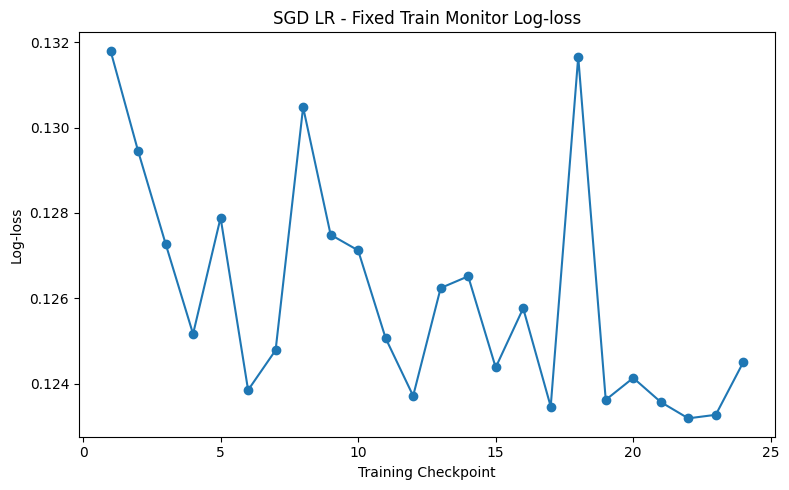

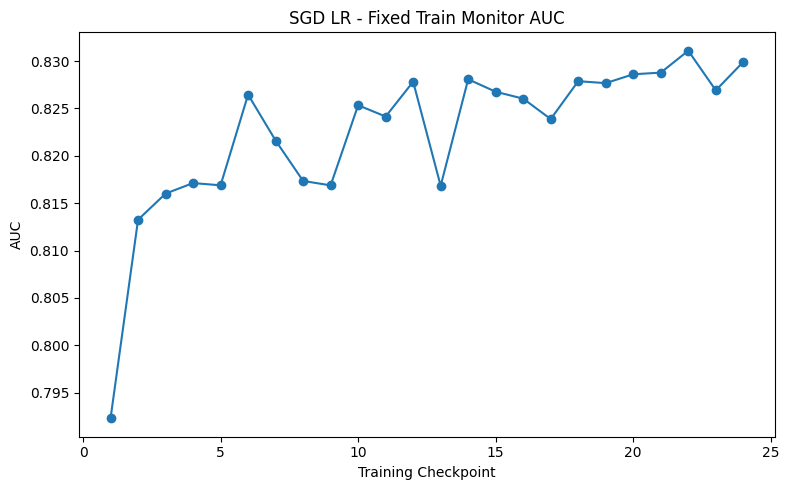

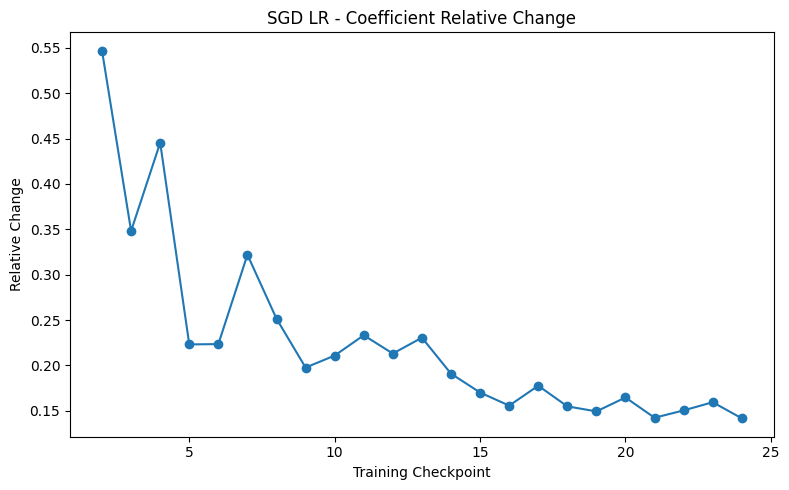

In [8]:
# ============================================================
# Full-data SGD Logistic Regression
#
# 前面的 Train-internal diagnosis 已经表明：
#
# eta0 = 1e-4
#
# 在当前 standardized feature space 下能够稳定学习。
#
# 这里重新建立一个全新的模型，
# 不继承 diagnosis model 的任何参数，
# 然后使用完整 Train 训练 baseline。
# ============================================================


# ------------------------------------------------------------
# 1. 正式 baseline
# ------------------------------------------------------------

sgd_lr = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=SGD_ALPHA,

    # Train-internal diagnosis 选择的学习率。
    learning_rate="constant",
    eta0=1e-4,

    # batch 内部的随机顺序由我们自己控制。
    shuffle=False,

    # PD 模型保留真实坏账比例。
    class_weight=None,

    # diagnosis 时没有使用 parameter averaging，
    # 正式 baseline 也保持一致。
    average=False,

    random_state=RANDOM_SEED,
)


# ------------------------------------------------------------
# 2. 记录训练过程
# ------------------------------------------------------------

training_history_rows = []

first_partial_fit = True

previous_checkpoint_coef = None

cumulative_rows_seen = 0


# ------------------------------------------------------------
# 3. Full Train
# ------------------------------------------------------------

for epoch in range(
    1,
    SGD_EPOCHS + 1,
):

    # 每个 epoch 使用一个不同但可重复的顺序。
    epoch_rng = np.random.default_rng(
        RANDOM_SEED + epoch
    )

    row_group_order = np.arange(
        train_parquet.num_row_groups
    )

    epoch_rng.shuffle(
        row_group_order
    )


    for position, row_group_id in enumerate(
        row_group_order,
        start=1,
    ):

        # ----------------------------------------------------
        # 读取一个完整 row group
        # ----------------------------------------------------

        batch = (
            train_parquet
            .read_row_group(
                int(row_group_id),
                columns=TRAIN_STREAM_COLUMNS,
                use_threads=True,
            )
            .to_pandas()
        )


        assert batch[
            ID_COL
        ].is_unique

        assert batch[
            TARGET_COL
        ].notna().all()


        # ----------------------------------------------------
        # 整行 shuffle
        #
        # X 和 y 此时仍在同一个 DataFrame，
        # 所以不会发生标签错位。
        # ----------------------------------------------------

        batch_rng = np.random.default_rng(
            RANDOM_SEED
            + epoch * 100_000
            + int(row_group_id)
        )

        permutation = batch_rng.permutation(
            len(batch)
        )

        batch = (
            batch
            .iloc[permutation]
            .reset_index(drop=True)
        )


        # ----------------------------------------------------
        # 拆出 y 和 transformed X
        # ----------------------------------------------------

        y_batch = (
            batch[
                TARGET_COL
            ]
            .to_numpy(
                dtype=np.int8
            )
        )


        X_batch = transform_sgd_batch(
            batch
        )


        assert (
            X_batch.shape[0]
            == len(y_batch)
            == batch[
                ID_COL
            ].nunique()
        ), (
            "X / y / case_id 行数不一致"
        )


        # ----------------------------------------------------
        # SGD update
        # ----------------------------------------------------

        if first_partial_fit:

            sgd_lr.partial_fit(
                X_batch,
                y_batch,
                classes=classes,
            )

            first_partial_fit = False

        else:

            sgd_lr.partial_fit(
                X_batch,
                y_batch,
            )


        cumulative_rows_seen += len(
            y_batch
        )


        # ----------------------------------------------------
        # Fixed Train Monitor
        #
        # 每隔 20 个 row groups，
        # 用同一批 20,000 Train 样本
        # 检查当前模型。
        # ----------------------------------------------------

        make_checkpoint = (
            position
            % SGD_MONITOR_EVERY_ROW_GROUPS
            == 0

            or

            position
            == len(row_group_order)
        )


        if make_checkpoint:

            monitor_pred = (
                sgd_lr
                .predict_proba(
                    X_sgd_monitor
                )[:, 1]
            )


            monitor_logloss = log_loss(
                y_sgd_monitor,
                np.clip(
                    monitor_pred,
                    1e-12,
                    1 - 1e-12,
                ),
                labels=[0, 1],
            )


            monitor_auc = roc_auc_score(
                y_sgd_monitor,
                monitor_pred,
            )


            current_coef = (
                sgd_lr.coef_
                .astype(
                    np.float64,
                    copy=True,
                )
            )


            # ------------------------------------------------
            # coefficient relative change
            # ------------------------------------------------

            if (
                previous_checkpoint_coef
                is None
            ):

                coef_relative_change = (
                    np.nan
                )

            else:

                denominator = max(
                    np.linalg.norm(
                        previous_checkpoint_coef
                    ),
                    1e-12,
                )

                coef_relative_change = float(
                    np.linalg.norm(
                        current_coef
                        - previous_checkpoint_coef
                    )
                    / denominator
                )


            # ------------------------------------------------
            # 保存 checkpoint
            # ------------------------------------------------

            training_history_rows.append({
                "epoch": epoch,

                "row_groups_seen_in_epoch": (
                    position
                ),

                "train_rows_seen_cumulative": (
                    cumulative_rows_seen
                ),

                "monitor_train_logloss": (
                    float(
                        monitor_logloss
                    )
                ),

                "monitor_train_auc": (
                    float(
                        monitor_auc
                    )
                ),

                "monitor_mean_pd": (
                    float(
                        monitor_pred.mean()
                    )
                ),

                "monitor_prediction_std": (
                    float(
                        monitor_pred.std()
                    )
                ),

                "coef_relative_change": (
                    coef_relative_change
                ),
            })


            previous_checkpoint_coef = (
                current_coef
            )


            print(
                f"Epoch {epoch}  "
                f"row groups "
                f"{position:,} / "
                f"{len(row_group_order):,}  "
                f"logloss="
                f"{monitor_logloss:.6f}  "
                f"AUC="
                f"{monitor_auc:.6f}  "
                f"mean_PD="
                f"{monitor_pred.mean():.6f}"
            )


            del (
                monitor_pred,
                current_coef,
            )


        # ----------------------------------------------------
        # 释放本 batch
        # ----------------------------------------------------

        del (
            batch,
            X_batch,
            y_batch,
            permutation,
        )

        gc.collect()


# ------------------------------------------------------------
# 4. Training History
# ------------------------------------------------------------

sgd_training_history = pd.DataFrame(
    training_history_rows
)


display(
    sgd_training_history
)


sgd_training_history.to_csv(
    REPORT_ROOT
    / "sgd_training_history.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. Convergence curves
# ------------------------------------------------------------

checkpoint_number = np.arange(
    1,
    len(
        sgd_training_history
    ) + 1,
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    checkpoint_number,
    sgd_training_history[
        "monitor_train_logloss"
    ],
    marker="o",
)

plt.title(
    "SGD LR - Fixed Train Monitor Log-loss"
)

plt.xlabel(
    "Training Checkpoint"
)

plt.ylabel(
    "Log-loss"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    checkpoint_number,
    sgd_training_history[
        "monitor_train_auc"
    ],
    marker="o",
)

plt.title(
    "SGD LR - Fixed Train Monitor AUC"
)

plt.xlabel(
    "Training Checkpoint"
)

plt.ylabel(
    "AUC"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    checkpoint_number,
    sgd_training_history[
        "coef_relative_change"
    ],
    marker="o",
)

plt.title(
    "SGD LR - Coefficient Relative Change"
)

plt.xlabel(
    "Training Checkpoint"
)

plt.ylabel(
    "Relative Change"
)

plt.tight_layout()
plt.show()

## 7. Full Train 与 Validation 预测

模型训练完成后，再单独做一次流式预测。

这里不会重新训练模型，只是让冻结后的模型依次读取完整 Train 与 Validation，并保存：

```text
case_id
WEEK_NUM
target
predicted_pd
```

预测结果一旦生成，就立即与原来的 `case_id` 和 `target` 放回同一张表中。

这样后面的 AUC、Gini、KS、Calibration 和 weekly metrics 都基于明确的样本身份，不需要依赖裸预测数组的隐含顺序。

Train 预测用于建立基准模型的训练表现；Validation 预测则用于真正的未来时间段评价。

In [9]:
def stream_predict_sgd(
    parquet_path,
    prediction_column,
):
    '''
    按 Parquet row group 生成预测。
    不 shuffle，保持原始 case_id 顺序。
    '''

    parquet_file = pq.ParquetFile(
        parquet_path
    )

    prediction_parts = []

    prediction_columns = [
        ID_COL,
        WEEK_COL,
        TARGET_COL,
        *candidate_features,
    ]

    for row_group_id in range(
        parquet_file.num_row_groups
    ):

        batch = (
            parquet_file
            .read_row_group(
                row_group_id,
                columns=prediction_columns,
                use_threads=True,
            )
            .to_pandas()
        )

        assert batch[ID_COL].is_unique
        assert batch[TARGET_COL].notna().all()

        X_batch = transform_sgd_batch(
            batch
        )

        prediction = (
            sgd_lr
            .predict_proba(
                X_batch
            )[:, 1]
            .astype(np.float32)
        )

        assert len(prediction) == len(
            batch
        )

        output = batch[
            [
                ID_COL,
                WEEK_COL,
                TARGET_COL,
            ]
        ].copy()

        output[
            prediction_column
        ] = prediction

        prediction_parts.append(
            output
        )

        del (
            batch,
            X_batch,
            prediction,
            output,
        )

        gc.collect()


        if (
            (row_group_id + 1)
            % 20 == 0
            or row_group_id + 1
            == parquet_file.num_row_groups
        ):
            print(
                f"{Path(parquet_path).name}  "
                f"row groups "
                f"{row_group_id + 1:,} / "
                f"{parquet_file.num_row_groups:,}"
            )


    result = pd.concat(
        prediction_parts,
        ignore_index=True,
    )

    assert result[ID_COL].is_unique

    return result


train_sgd_predictions = (
    stream_predict_sgd(
        TRAIN_PATH,
        "sgd_lr_pred",
    )
)

validation_predictions = (
    stream_predict_sgd(
        VALIDATION_PATH,
        "sgd_lr_pred",
    )
)


print(
    "Full Train predictions：",
    len(train_sgd_predictions),
)

print(
    "Validation predictions：",
    len(validation_predictions),
)

train_clean.parquet  row groups 20 / 153
train_clean.parquet  row groups 40 / 153
train_clean.parquet  row groups 60 / 153
train_clean.parquet  row groups 80 / 153
train_clean.parquet  row groups 100 / 153
train_clean.parquet  row groups 120 / 153
train_clean.parquet  row groups 140 / 153
train_clean.parquet  row groups 153 / 153
validation_clean.parquet  row groups 20 / 56
validation_clean.parquet  row groups 40 / 56
validation_clean.parquet  row groups 56 / 56
Full Train predictions： 1282082
Validation predictions： 92870


## 8. 整体排序能力与概率校准

Full-data SGD Logistic Regression 建立以后，先比较模型在完整 Train 与未来 Validation 上的整体表现。

评价分成两个不同维度。

### 排序能力

- AUC
- Gini
- KS

它们回答：

> 高风险客户是否整体排在低风险客户前面？

其中 Gini 是 AUC 的线性转换，因此两者不是两份独立证据；KS 则补充观察 Good / Bad 的最大分离程度。

### 概率校准

- Log-loss
- Brier Score
- Observed Bad Rate
- Mean Predicted PD
- O/E
- Calibration Intercept
- Calibration Slope
- Risk-group Calibration

它们回答：

> 模型预测出来的 PD 概率及其风险差异，是否与真实坏账结果相匹配？

理想情况下：

```text
Calibration Intercept ≈ 0
Calibration Slope     ≈ 1
O/E                   ≈ 1
```


In [10]:
from sklearn.linear_model import (
    LogisticRegression,
)
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    roc_curve,
)


def calculate_ks(
    y_true,
    y_score,
):
    fpr, tpr, _ = roc_curve(
        y_true,
        y_score,
    )
    return float(
        np.max(tpr - fpr)
    )


def calculate_calibration_intercept_slope(
    y_true,
    y_score,
):
    '''
    logit(y) = intercept + slope * logit(predicted PD)
    理想值：intercept = 0, slope = 1。
    '''
    y_true = np.asarray(
        y_true,
        dtype=np.int8,
    )
    probability = np.clip(
        np.asarray(
            y_score,
            dtype=np.float64,
        ),
        1e-6,
        1 - 1e-6,
    )
    predicted_logit = np.log(
        probability
        / (1.0 - probability)
    ).reshape(-1, 1)

    recalibration = LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=1000,
    )
    recalibration.fit(
        predicted_logit,
        y_true,
    )

    return (
        float(recalibration.intercept_[0]),
        float(recalibration.coef_[0, 0]),
    )


def evaluate_prediction_frame(
    frame,
    prediction_column,
    dataset_name,
    model_name,
):
    y_true = frame[TARGET_COL]
    y_score = frame[prediction_column]

    auc = roc_auc_score(
        y_true,
        y_score,
    )
    observed_bad_rate = float(
        y_true.mean()
    )
    mean_predicted_pd = float(
        y_score.mean()
    )
    oe_ratio = (
        observed_bad_rate
        / mean_predicted_pd
        if mean_predicted_pd > 0
        else np.nan
    )

    (
        calibration_intercept,
        calibration_slope,
    ) = calculate_calibration_intercept_slope(
        y_true,
        y_score,
    )

    return {
        "model": model_name,
        "dataset": dataset_name,
        "auc": auc,
        "gini": 2 * auc - 1,
        "ks": calculate_ks(
            y_true,
            y_score,
        ),
        "log_loss": log_loss(
            y_true,
            y_score,
            labels=[0, 1],
        ),
        "brier_score": brier_score_loss(
            y_true,
            y_score,
        ),
        "observed_bad_rate": observed_bad_rate,
        "mean_predicted_pd": mean_predicted_pd,
        "oe_ratio": oe_ratio,
        "calibration_intercept": (
            calibration_intercept
        ),
        "calibration_slope": calibration_slope,
    }


sgd_lr_metrics = pd.DataFrame([
    evaluate_prediction_frame(
        train_sgd_predictions,
        "sgd_lr_pred",
        "Train",
        "Full-data SGD LR",
    ),
    evaluate_prediction_frame(
        validation_predictions,
        "sgd_lr_pred",
        "Validation",
        "Full-data SGD LR",
    ),
])

display(sgd_lr_metrics)

,model,dataset,auc,gini,ks,log_loss,brier_score,observed_bad_rate,mean_predicted_pd,oe_ratio,calibration_intercept,calibration_slope
0,Full-data SGD LR,Train,0.829691,0.659383,0.506097,0.120988,0.029977,0.033168,0.032773,1.012063,-0.167396,0.933440
1,Full-data SGD LR,Validation,0.737423,0.474846,0.397748,0.117628,0.023696,0.024281,0.028206,0.860859,-1.859659,0.436598


In [11]:
# ------------------------------------------------------------
# Validation risk-group calibration
# ------------------------------------------------------------

calibration_data = (
    validation_predictions[
        [
            TARGET_COL,
            "sgd_lr_pred",
        ]
    ]
    .copy()
)


calibration_data[
    "risk_group"
] = pd.qcut(
    calibration_data[
        "sgd_lr_pred"
    ],
    q=10,
    duplicates="drop",
)


sgd_lr_calibration = (
    calibration_data
    .groupby(
        "risk_group",
        observed=True,
    )
    .agg(
        sample_count=(
            TARGET_COL,
            "size",
        ),
        mean_predicted_pd=(
            "sgd_lr_pred",
            "mean",
        ),
        observed_bad_rate=(
            TARGET_COL,
            "mean",
        ),
    )
    .reset_index()
)


sgd_lr_calibration[
    "oe_ratio"
] = (
    sgd_lr_calibration[
        "observed_bad_rate"
    ]
    / sgd_lr_calibration[
        "mean_predicted_pd"
    ]
)


display(
    sgd_lr_calibration
)

,risk_group,sample_count,mean_predicted_pd,observed_bad_rate,oe_ratio
0,"(-0.001, 0.000423]",9287,0.000110,0.017336,158.087618
1,"(0.000423, 0.00174]",9287,0.001039,0.006999,6.738985
2,"(0.00174, 0.00358]",9287,0.002634,0.006891,2.616784
3,"(0.00358, 0.00597]",9287,0.004712,0.008614,1.828068
4,"(0.00597, 0.00928]",9287,0.007544,0.008830,1.170333
5,"(0.00928, 0.0139]",9287,0.011449,0.011845,1.034582
6,"(0.0139, 0.0211]",9287,0.017225,0.018413,1.068950
7,"(0.0211, 0.0341]",9287,0.026926,0.021859,0.811802
8,"(0.0341, 0.0675]",9287,0.047687,0.042748,0.896423
9,"(0.0675, 0.966]",9287,0.162733,0.099279,0.610070


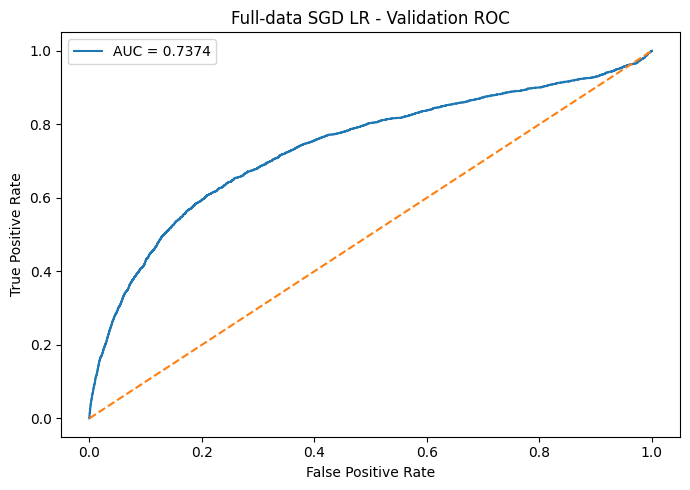

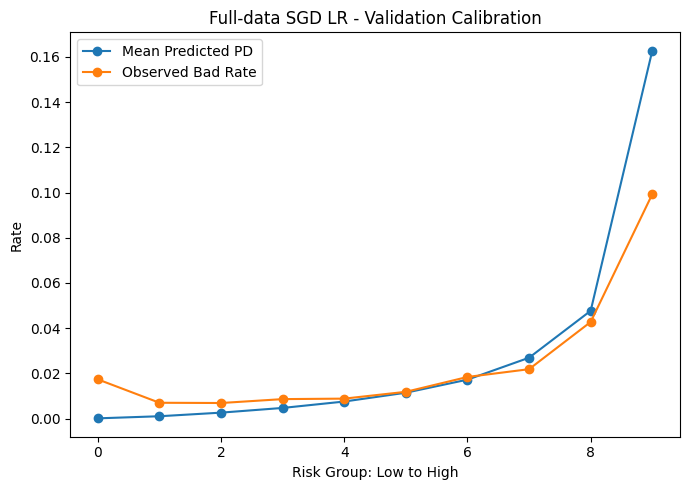

In [12]:
# ------------------------------------------------------------
# Validation ROC
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    validation_predictions[
        TARGET_COL
    ],
    validation_predictions[
        "sgd_lr_pred"
    ],
)

validation_auc = roc_auc_score(
    validation_predictions[
        TARGET_COL
    ],
    validation_predictions[
        "sgd_lr_pred"
    ],
)


plt.figure(
    figsize=(7, 5)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"AUC = {validation_auc:.4f}"
    ),
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

plt.title(
    "Full-data SGD LR - Validation ROC"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Validation calibration
# ------------------------------------------------------------

x = np.arange(
    len(sgd_lr_calibration)
)

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    x,
    sgd_lr_calibration[
        "mean_predicted_pd"
    ],
    marker="o",
    label="Mean Predicted PD",
)

plt.plot(
    x,
    sgd_lr_calibration[
        "observed_bad_rate"
    ],
    marker="o",
    label="Observed Bad Rate",
)

plt.title(
    "Full-data SGD LR - Validation Calibration"
)

plt.xlabel(
    "Risk Group: Low to High"
)

plt.ylabel(
    "Rate"
)

plt.legend()
plt.tight_layout()
plt.show()

## 9. Validation 时间表现评估

整体 Validation 指标只能告诉我们 Week 64–77 合在一起之后的平均表现，但不能回答模型表现是否随着时间持续变化。

因此进一步按照 `WEEK_NUM` 拆分 Validation，分别观察 SGD Logistic Regression 和 LightGBM 在不同周上的：

- Sample Count
- Bad Count
- AUC / Gini
- Observed Bad Rate
- Mean Predicted PD
- O/E
- AUC 95% Bootstrap CI
- O/E 95% Bootstrap CI

这里加入置信区间非常重要。部分周的样本量和 Bad Count 较少，因此单周 AUC 的波动可能同时受到真实时间变化和 sampling uncertainty 的影响。

### Weekly Discrimination

SGD Logistic Regression 的 weekly AUC 并没有从 Week 64 到 Week 77 持续、单调下降。

Validation 开始时：

```text
Week 64  AUC ≈ 0.806
Week 65  AUC ≈ 0.824
```


In [13]:
def bootstrap_weekly_ci(
    y_true,
    y_score,
    seed,
):
    '''
    同一周做 non-parametric bootstrap，
    同时给 AUC 与 O/E 95% uncertainty range。
    '''
    y_true = np.asarray(
        y_true,
        dtype=np.int8,
    )
    y_score = np.asarray(
        y_score,
        dtype=np.float64,
    )

    rng = np.random.default_rng(seed)
    auc_values = []
    oe_values = []

    for _ in range(
        WEEKLY_BOOTSTRAP_ROUNDS
    ):
        indices = rng.integers(
            0,
            len(y_true),
            size=len(y_true),
        )
        y_boot = y_true[indices]
        score_boot = y_score[indices]

        if np.unique(y_boot).size >= 2:
            auc_values.append(
                roc_auc_score(
                    y_boot,
                    score_boot,
                )
            )

        mean_pred = score_boot.mean()
        if mean_pred > 0:
            oe_values.append(
                y_boot.mean() / mean_pred
            )

    def percentile_interval(values):
        if len(values) == 0:
            return np.nan, np.nan
        lower, upper = np.percentile(
            values,
            [2.5, 97.5],
        )
        return float(lower), float(upper)

    auc_lower, auc_upper = (
        percentile_interval(auc_values)
    )
    oe_lower, oe_upper = (
        percentile_interval(oe_values)
    )

    return (
        auc_lower,
        auc_upper,
        oe_lower,
        oe_upper,
    )


def evaluate_by_week(
    frame,
    prediction_column,
    model_name,
):
    rows = []

    for week, group in frame.groupby(
        WEEK_COL,
        sort=True,
    ):
        y_true = group[TARGET_COL]
        y_score = group[prediction_column]

        if y_true.nunique() >= 2:
            auc = roc_auc_score(
                y_true,
                y_score,
            )
        else:
            auc = np.nan

        observed_bad_rate = float(
            y_true.mean()
        )
        mean_predicted_pd = float(
            y_score.mean()
        )
        oe_ratio = (
            observed_bad_rate
            / mean_predicted_pd
            if mean_predicted_pd > 0
            else np.nan
        )

        (
            auc_ci_lower,
            auc_ci_upper,
            oe_ci_lower,
            oe_ci_upper,
        ) = bootstrap_weekly_ci(
            y_true,
            y_score,
            seed=RANDOM_SEED + int(week),
        )

        rows.append({
            "model": model_name,
            WEEK_COL: int(week),
            "sample_count": len(group),
            "bad_count": int(y_true.sum()),
            "auc": auc,
            "auc_ci_lower": auc_ci_lower,
            "auc_ci_upper": auc_ci_upper,
            "gini": (
                2 * auc - 1
                if pd.notna(auc)
                else np.nan
            ),
            "observed_bad_rate": observed_bad_rate,
            "mean_predicted_pd": mean_predicted_pd,
            "oe_ratio": oe_ratio,
            "oe_ci_lower": oe_ci_lower,
            "oe_ci_upper": oe_ci_upper,
        })

    return pd.DataFrame(rows)


weekly_sgd_metrics = evaluate_by_week(
    validation_predictions,
    "sgd_lr_pred",
    "Full-data SGD LR",
)

display(weekly_sgd_metrics)

,model,WEEK_NUM,sample_count,bad_count,auc,auc_ci_lower,auc_ci_upper,gini,observed_bad_rate,mean_predicted_pd,oe_ratio,oe_ci_lower,oe_ci_upper
0,Full-data SGD LR,64,10268,322,0.805970,0.782593,0.828928,0.611941,0.031360,0.040723,0.770064,0.693199,0.852891
1,Full-data SGD LR,65,4258,96,0.824158,0.778346,0.859110,0.648316,0.022546,0.034412,0.655179,0.527573,0.776515
2,Full-data SGD LR,66,2278,52,0.735011,0.666448,0.808442,0.470022,0.022827,0.033708,0.677198,0.500570,0.865325
3,Full-data SGD LR,67,1434,30,0.745893,0.620562,0.854381,0.491785,0.020921,0.028276,0.739865,0.496252,1.008397
4,Full-data SGD LR,68,825,21,0.698887,0.567927,0.814869,0.397773,0.025455,0.020329,1.252137,0.819112,1.741573
5,Full-data SGD LR,69,1582,35,0.675427,0.591675,0.783642,0.350854,0.022124,0.023134,0.956330,0.693726,1.316945
6,Full-data SGD LR,70,3808,82,0.701511,0.640098,0.769666,0.403022,0.021534,0.026948,0.799077,0.627597,0.989375
7,Full-data SGD LR,71,7921,176,0.762548,0.725669,0.806190,0.525095,0.022219,0.030940,0.718139,0.633754,0.813524
8,Full-data SGD LR,72,8858,207,0.737900,0.701326,0.773163,0.475800,0.023369,0.027096,0.862430,0.756864,0.983831
9,Full-data SGD LR,73,8687,189,0.668243,0.629446,0.711513,0.336486,0.021757,0.020760,1.047993,0.904424,1.212779


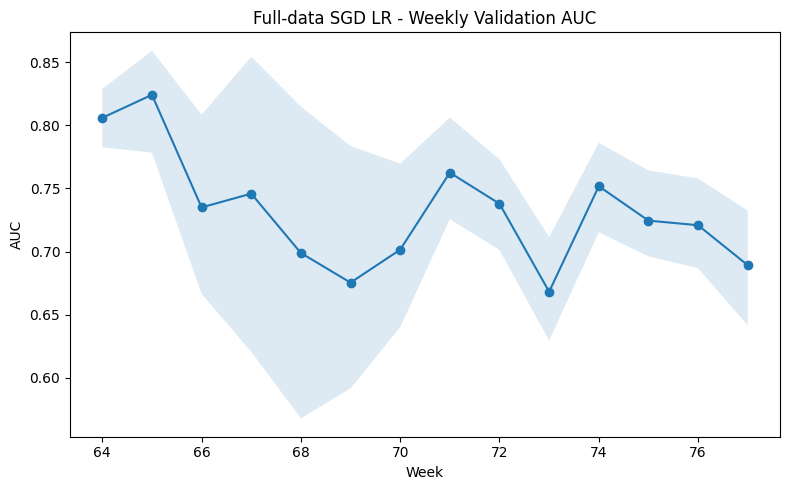

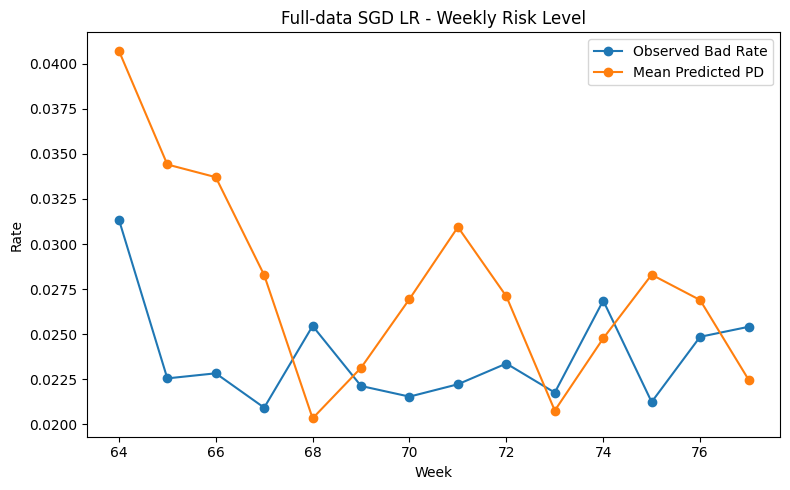

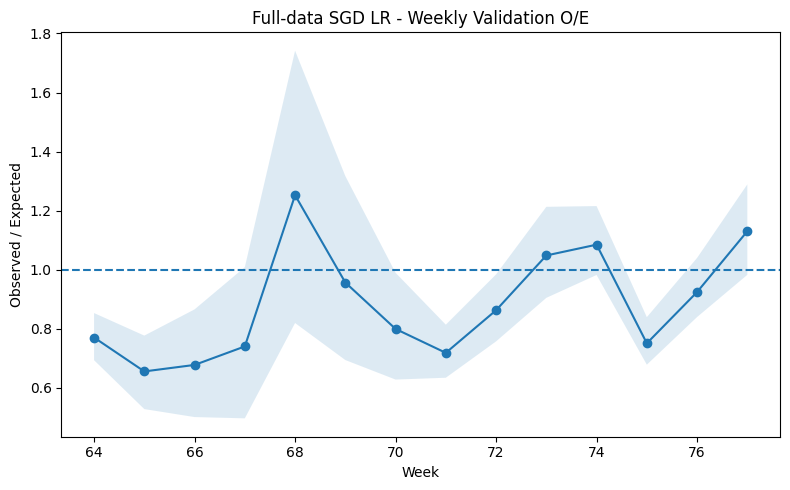

In [14]:
# ------------------------------------------------------------
# Weekly AUC + 95% CI
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["auc"],
    marker="o",
)
plt.fill_between(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["auc_ci_lower"],
    weekly_sgd_metrics["auc_ci_upper"],
    alpha=0.15,
)
plt.title(
    "Full-data SGD LR - Weekly Validation AUC"
)
plt.xlabel("Week")
plt.ylabel("AUC")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Weekly risk level
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["observed_bad_rate"],
    marker="o",
    label="Observed Bad Rate",
)
plt.plot(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["mean_predicted_pd"],
    marker="o",
    label="Mean Predicted PD",
)
plt.title(
    "Full-data SGD LR - Weekly Risk Level"
)
plt.xlabel("Week")
plt.ylabel("Rate")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Weekly O/E + 95% CI
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["oe_ratio"],
    marker="o",
)
plt.fill_between(
    weekly_sgd_metrics[WEEK_COL],
    weekly_sgd_metrics["oe_ci_lower"],
    weekly_sgd_metrics["oe_ci_upper"],
    alpha=0.15,
)
plt.axhline(
    1.0,
    linestyle="--",
)
plt.title(
    "Full-data SGD LR - Weekly Validation O/E"
)
plt.xlabel("Week")
plt.ylabel("Observed / Expected")
plt.tight_layout()
plt.show()

## 10. LGBM 参考模型

Full-data SGD LR 完成以后，再建立一个全量 LightGBM nonlinear reference / challenger。

它不是第二个 baseline。LR 负责给出简单线性参照；LightGBM 则回答：

> **如果允许模型学习非线性关系和 feature interaction，同一批合法候选特征还能多提供多少预测信息？**

LightGBM 不需要使用 LR 的 One-Hot 矩阵。Numerical 可以直接保留原始数值和 NaN，Categorical / Boolean 则使用前面已经冻结的类别规则转换为稳定的 category code。

为了避免重新把完整宽表一次性放进 Pandas，这里继续使用 LightGBM 的 `Sequence` 接口：

```text
Parquet
→ 需要哪一段时再读取哪一段
→ LightGBM 构建内部 Dataset
→ 全部 Train 样本参与 boosting
```

### Boosting rounds 不再固定为 300

`num_boost_round=300` 本身没有数据依据。现在改成：

```text
较大的 max_boost_round
        ↓
每轮观察 Validation binary_logloss
        ↓
连续一段时间没有改善
        ↓
early stopping
        ↓
best_iteration
```

`binary_logloss` 作为 stopping 主指标，是因为这里不仅关心排序，还把输出解释为 PD 概率；AUC 仍然同时记录，用来比较 discrimination。

### 50k bin sample 只做轻量验证

`bin_construct_sample_cnt` 只控制 LightGBM 建立分箱边界时抽取多少行，它不代表训练抽样。当前仍以 `50,000` 作为资源友好的默认值，同时提供一个可选的小实验，与更大的 sample count 比较 Validation log-loss / AUC。如果差异很小，就继续保留 50k；如果差异明显，再提高。

这一部分与 LR 是两个不同算法的 reference，因此 preprocessing 不要求完全相同。真正需要保持一致的是：

```text
同一 Train 时间范围
同一 Validation 时间范围
同一 Eligible Raw Candidate Feature Pool
OOT 不参与
```

In [15]:
import lightgbm as lgb


# LR 的完整 Train prediction 之后不再需要，
# 先释放，给 LightGBM 留出内存。
del train_sgd_predictions
gc.collect()


class ParquetLGBMSequence(
    lgb.Sequence
):
    '''
    用 Parquet row group 为 LightGBM 提供流式数据。

    输出列顺序固定为：
    numerical + categorical_code
    '''

    batch_size = 4096

    def __init__(
        self,
        parquet_path,
        numeric_features,
        categorical_features,
        categorical_rules,
    ):

        self.parquet_path = Path(
            parquet_path
        )

        self.parquet_file = (
            pq.ParquetFile(
                parquet_path
            )
        )

        self.numeric_features = list(
            numeric_features
        )

        self.categorical_features = list(
            categorical_features
        )

        self.categorical_rules = (
            categorical_rules
        )

        self.feature_columns = [
            *self.numeric_features,
            *self.categorical_features,
        ]

        self.row_group_sizes = np.array([
            self.parquet_file
            .metadata
            .row_group(i)
            .num_rows
            for i in range(
                self.parquet_file
                .num_row_groups
            )
        ])

        self.row_group_starts = (
            np.concatenate([
                np.array([0]),
                np.cumsum(
                    self.row_group_sizes
                ),
            ])
        )

        self.total_rows = int(
            self.row_group_starts[-1]
        )

        # LightGBM sample indices 是单调读取的，
        # 缓存当前 row group 可以避免重复 I/O。
        self._cache_row_group = None
        self._cache_matrix = None


    def __len__(self):
        return self.total_rows


    def _convert_row_group(
        self,
        row_group_id,
    ):

        frame = (
            self.parquet_file
            .read_row_group(
                int(row_group_id),
                columns=(
                    self.feature_columns
                ),
                use_threads=True,
            )
            .to_pandas()
        )

        numerical = (
            frame[
                self.numeric_features
            ]
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan,
            )
        )


        categorical_arrays = []

        for feature in (
            self.categorical_features
        ):

            series = (
                frame[feature]
                .astype("string")
                .fillna(
                    MISSING_TOKEN
                )
            )

            kept_set = (
                self.categorical_rules[
                    feature
                ]["kept_set"]
            )

            series = series.where(
                series.isin(
                    kept_set
                ),
                RARE_TOKEN,
            )

            categories = (
                self.categorical_rules[
                    feature
                ]["categories"]
            )

            codes = (
                pd.Categorical(
                    series,
                    categories=categories,
                )
                .codes
                .astype(
                    np.float32
                )
            )

            categorical_arrays.append(
                codes
            )


        if categorical_arrays:

            categorical_matrix = (
                np.column_stack(
                    categorical_arrays
                )
                .astype(
                    np.float32,
                    copy=False,
                )
            )

            matrix = np.hstack([
                numerical,
                categorical_matrix,
            ])

        else:
            matrix = numerical


        del frame

        return np.asarray(
            matrix,
            dtype=np.float32,
            order="C",
        )


    def _get_row_group_matrix(
        self,
        row_group_id,
    ):

        if (
            self._cache_row_group
            != row_group_id
        ):

            self._cache_matrix = (
                self._convert_row_group(
                    row_group_id
                )
            )

            self._cache_row_group = (
                row_group_id
            )

        return self._cache_matrix


    def _locate_row_group(
        self,
        row_index,
    ):

        row_group_id = int(
            np.searchsorted(
                self.row_group_starts[
                    1:
                ],
                row_index,
                side="right",
            )
        )

        local_index = int(
            row_index
            - self.row_group_starts[
                row_group_id
            ]
        )

        return (
            row_group_id,
            local_index,
        )


    def __getitem__(
        self,
        idx,
    ):

        if isinstance(
            idx,
            (int, np.integer),
        ):

            if idx < 0:
                idx += len(self)

            row_group_id, local_index = (
                self._locate_row_group(
                    int(idx)
                )
            )

            matrix = (
                self._get_row_group_matrix(
                    row_group_id
                )
            )

            return matrix[
                    local_index
                ].astype(
                    np.float64,
                    copy=False,
                )


        if isinstance(
            idx,
            slice,
        ):

            start = (
                0
                if idx.start is None
                else int(idx.start)
            )

            stop = (
                len(self)
                if idx.stop is None
                else int(idx.stop)
            )

            if (
                idx.step
                not in (None, 1)
            ):
                indices = list(
                    range(
                        start,
                        stop,
                        idx.step,
                    )
                )

                return self[
                    indices
                ]

            parts = []

            current = start

            while current < stop:

                (
                    row_group_id,
                    local_start,
                ) = self._locate_row_group(
                    current
                )

                matrix = (
                    self._get_row_group_matrix(
                        row_group_id
                    )
                )

                available = (
                    len(matrix)
                    - local_start
                )

                take = min(
                    available,
                    stop - current,
                )

                parts.append(
                    matrix[
                        local_start:
                        local_start + take
                    ]
                )

                current += take


            if not parts:
                return np.empty(
                    (
                        0,
                        len(
                            self.feature_columns
                        ),
                    ),
                    dtype=np.float32,
                )

            if len(parts) == 1:
                return parts[0]

            return np.vstack(
                parts
            )


        if isinstance(
            idx,
            list,
        ):

            return np.stack([
                self[int(i)]
                for i in idx
            ])


        raise TypeError(
            f"Unsupported index type："
            f"{type(idx)}"
        )


lgbm_feature_names = [
    *numeric_features,
    *categorical_features,
]


lgbm_categorical_indices = list(
    range(
        len(numeric_features),
        len(lgbm_feature_names),
    )
)


train_lgb_sequence = (
    ParquetLGBMSequence(
        TRAIN_PATH,
        numeric_features,
        categorical_features,
        categorical_rules,
    )
)

validation_lgb_sequence = (
    ParquetLGBMSequence(
        VALIDATION_PATH,
        numeric_features,
        categorical_features,
        categorical_rules,
    )
)


train_labels_lgb = (
    pd.read_parquet(
        TRAIN_PATH,
        columns=[TARGET_COL],
        engine="pyarrow",
    )[TARGET_COL]
    .to_numpy(
        dtype=np.int8
    )
)

validation_labels_lgb = (
    pd.read_parquet(
        VALIDATION_PATH,
        columns=[TARGET_COL],
        engine="pyarrow",
    )[TARGET_COL]
    .to_numpy(
        dtype=np.int8
    )
)


assert (
    len(train_lgb_sequence)
    == len(train_labels_lgb)
)

assert (
    len(validation_lgb_sequence)
    == len(validation_labels_lgb)
)

### bin_construct_sample_cnt 轻量验证

这一小段不是完整 hyperparameter tuning，只回答一个工程问题：`50,000` 个 bin-construction samples 是否已经足够稳定。

默认 `RUN_LGBM_BIN_AUDIT=False`，因此正常跑 Notebook 不会额外训练模型。需要验证时改成 `True`，只比较 `50k` 与 `200k`，其他 LightGBM 设置保持一致。

In [16]:
bin_sample_audit_rows = []

if RUN_LGBM_BIN_AUDIT:
    for bin_sample_count in (
        LGBM_BIN_AUDIT_COUNTS
    ):
        audit_train_dataset = lgb.Dataset(
            train_lgb_sequence,
            label=train_labels_lgb,
            feature_name=lgbm_feature_names,
            categorical_feature=(
                lgbm_categorical_indices
            ),
            free_raw_data=True,
            params={
                "bin_construct_sample_cnt": (
                    bin_sample_count
                ),
                "max_bin": LGBM_MAX_BIN,
                "data_random_seed": RANDOM_SEED,
            },
        )

        audit_validation_dataset = lgb.Dataset(
            validation_lgb_sequence,
            label=validation_labels_lgb,
            reference=audit_train_dataset,
            feature_name=lgbm_feature_names,
            categorical_feature=(
                lgbm_categorical_indices
            ),
            free_raw_data=True,
        )

        audit_model = lgb.train(
            params={
                "objective": "binary",
                "metric": [
                    "binary_logloss",
                    "auc",
                ],
                "learning_rate": 0.05,
                "num_leaves": 31,
                "feature_fraction": 0.8,
                "bagging_fraction": 0.8,
                "bagging_freq": 1,
                "lambda_l2": 1.0,
                "seed": RANDOM_SEED,
                "device_type": LGBM_DEVICE_TYPE,
                "verbosity": -1,
                "num_threads": -1,
            },
            train_set=audit_train_dataset,
            num_boost_round=(
                LGBM_BIN_AUDIT_MAX_ROUNDS
            ),
            valid_sets=[
                audit_validation_dataset,
            ],
            valid_names=["Validation"],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=(
                        LGBM_BIN_AUDIT_EARLY_STOPPING_ROUNDS
                    ),
                    first_metric_only=True,
                    verbose=False,
                )
            ],
        )

        bin_sample_audit_rows.append({
            "bin_construct_sample_cnt": (
                bin_sample_count
            ),
            "best_iteration": (
                audit_model.best_iteration
            ),
            "validation_binary_logloss": (
                audit_model.best_score[
                    "Validation"
                ]["binary_logloss"]
            ),
            "validation_auc": (
                audit_model.best_score[
                    "Validation"
                ]["auc"]
            ),
        })

        del (
            audit_model,
            audit_train_dataset,
            audit_validation_dataset,
        )
        gc.collect()

bin_sample_audit = pd.DataFrame(
    bin_sample_audit_rows
)

if not bin_sample_audit.empty:
    display(bin_sample_audit)

[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.


/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2535: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")
/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2535: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


,bin_construct_sample_cnt,best_iteration,validation_binary_logloss,validation_auc
0,50000,200,0.095421,0.849536
1,200000,276,0.095245,0.850255


/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2535: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


Training until validation scores don't improve for 100 rounds
[50]	Train's binary_logloss: 0.122091	Train's auc: 0.834009	Validation's binary_logloss: 0.098917	Validation's auc: 0.830774
[100]	Train's binary_logloss: 0.116533	Train's auc: 0.853256	Validation's binary_logloss: 0.0965818	Validation's auc: 0.842727
[150]	Train's binary_logloss: 0.113507	Train's auc: 0.863728	Validation's binary_logloss: 0.0957956	Validation's auc: 0.846901
[200]	Train's binary_logloss: 0.111336	Train's auc: 0.871191	Validation's binary_logloss: 0.0955431	Validation's auc: 0.849128
[250]	Train's binary_logloss: 0.109552	Train's auc: 0.877164	Validation's binary_logloss: 0.0953373	Validation's auc: 0.850601
[300]	Train's binary_logloss: 0.108035	Train's auc: 0.882281	Validation's binary_logloss: 0.0952058	Validation's auc: 0.851754
[350]	Train's binary_logloss: 0.106688	Train's auc: 0.886727	Validation's binary_logloss: 0.0952463	Validation's auc: 0.851999
[400]	Train's binary_logloss: 0.105462	Train's auc:

,iteration,validation_binary_logloss,validation_auc,train_binary_logloss,train_auc
1131,1132,0.094291,0.852031,0.092740,0.927564
1132,1133,0.094286,0.852058,0.092726,0.927588
1133,1134,0.094277,0.852105,0.092708,0.927627
1134,1135,0.094268,0.852121,0.092692,0.927649
1135,1136,0.094273,0.852108,0.092670,0.927710
1136,1137,0.094266,0.852103,0.092656,0.927733
1137,1138,0.094257,0.852131,0.092641,0.927775
1138,1139,0.094253,0.852156,0.092628,0.927806
1139,1140,0.094252,0.852155,0.092614,0.927863
1140,1141,0.094253,0.852154,0.092601,0.927895


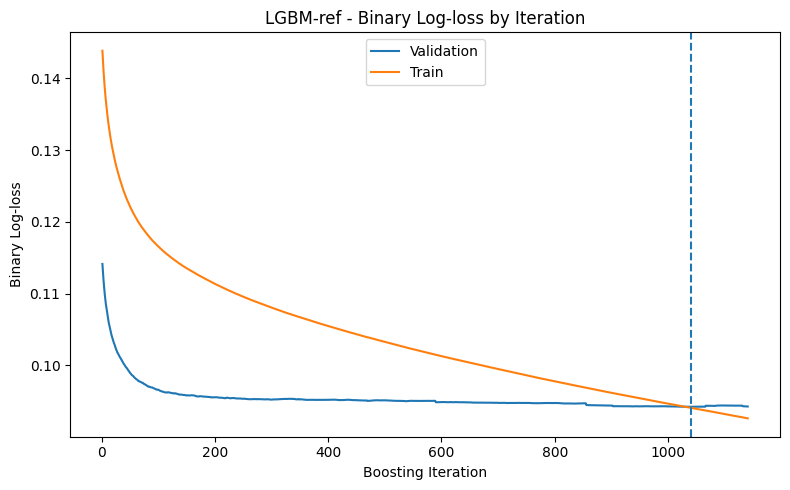

In [17]:
lgbm_dataset_params = {
    "bin_construct_sample_cnt": (
        LGBM_BIN_SAMPLE_COUNT
    ),
    "max_bin": LGBM_MAX_BIN,
    "data_random_seed": RANDOM_SEED,
}

train_lgb_dataset = lgb.Dataset(
    train_lgb_sequence,
    label=train_labels_lgb,
    feature_name=lgbm_feature_names,
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
    params=lgbm_dataset_params,
)

validation_lgb_dataset = lgb.Dataset(
    validation_lgb_sequence,
    label=validation_labels_lgb,
    reference=train_lgb_dataset,
    feature_name=lgbm_feature_names,
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
)

lgbm_params = {
    "objective": "binary",
    # 第一项作为 early-stopping 主指标。
    "metric": [
        "binary_logloss",
        "auc",
    ],
    "learning_rate": 0.05,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "seed": RANDOM_SEED,
    "device_type": LGBM_DEVICE_TYPE,
    "verbosity": -1,
    "num_threads": -1,
}

lgbm_evals_result = {}

lgbm_ref = lgb.train(
    params=lgbm_params,
    train_set=train_lgb_dataset,
    num_boost_round=LGBM_MAX_BOOST_ROUND,
    valid_sets=[
        validation_lgb_dataset,
        train_lgb_dataset,
    ],
    valid_names=[
        "Validation",
        "Train",
    ],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=(
                LGBM_EARLY_STOPPING_ROUNDS
            ),
            first_metric_only=True,
            verbose=True,
        ),
        lgb.record_evaluation(
            lgbm_evals_result
        ),
        lgb.log_evaluation(period=50),
    ],
)

print(
    "Full-data LGBM-ref training completed."
)
print(
    "Best iteration：",
    lgbm_ref.best_iteration,
)

lgbm_training_history = pd.DataFrame({
    "iteration": np.arange(
        1,
        len(
            lgbm_evals_result[
                "Validation"
            ]["binary_logloss"]
        ) + 1,
    ),
    "validation_binary_logloss": (
        lgbm_evals_result[
            "Validation"
        ]["binary_logloss"]
    ),
    "validation_auc": (
        lgbm_evals_result[
            "Validation"
        ]["auc"]
    ),
    "train_binary_logloss": (
        lgbm_evals_result[
            "Train"
        ]["binary_logloss"]
    ),
    "train_auc": (
        lgbm_evals_result[
            "Train"
        ]["auc"]
    ),
})

display(
    lgbm_training_history.tail(10)
)

plt.figure(figsize=(8, 5))
plt.plot(
    lgbm_training_history["iteration"],
    lgbm_training_history[
        "validation_binary_logloss"
    ],
    label="Validation",
)
plt.plot(
    lgbm_training_history["iteration"],
    lgbm_training_history[
        "train_binary_logloss"
    ],
    label="Train",
)
plt.axvline(
    lgbm_ref.best_iteration,
    linestyle="--",
)
plt.title(
    "LGBM-ref - Binary Log-loss by Iteration"
)
plt.xlabel("Boosting Iteration")
plt.ylabel("Binary Log-loss")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
def stream_predict_lgbm(
    booster,
    sequence,
    batch_size=20_000,
):

    predictions = []

    for start in range(
        0,
        len(sequence),
        batch_size,
    ):

        end = min(
            start + batch_size,
            len(sequence),
        )

        matrix = sequence[
            start:end
        ]

        pred = booster.predict(
            matrix,
            num_iteration=(
                booster.best_iteration
            ),
        ).astype(
            np.float32
        )

        predictions.append(
            pred
        )

        del matrix, pred
        gc.collect()


    return np.concatenate(
        predictions
    )


train_lgb_pred = (
    stream_predict_lgbm(
        lgbm_ref,
        train_lgb_sequence,
    )
)

validation_lgb_pred = (
    stream_predict_lgbm(
        lgbm_ref,
        validation_lgb_sequence,
    )
)


validation_predictions[
    "lgbm_ref_pred"
] = validation_lgb_pred


lgbm_train_frame = pd.DataFrame({
    TARGET_COL: train_labels_lgb,
    "lgbm_ref_pred": train_lgb_pred,
})


lgbm_ref_metrics = pd.DataFrame([
    evaluate_prediction_frame(
        lgbm_train_frame,
        "lgbm_ref_pred",
        "Train",
        "LGBM-ref",
    ),
    evaluate_prediction_frame(
        validation_predictions,
        "lgbm_ref_pred",
        "Validation",
        "LGBM-ref",
    ),
])


weekly_lgbm_metrics = (
    evaluate_by_week(
        validation_predictions,
        "lgbm_ref_pred",
        "LGBM-ref",
    )
)


display(
    lgbm_ref_metrics
)


del (
    lgbm_train_frame,
    train_lgb_pred,
)

gc.collect()

,model,dataset,auc,gini,ks,log_loss,brier_score,observed_bad_rate,mean_predicted_pd,oe_ratio,calibration_intercept,calibration_slope
0,LGBM-ref,Train,0.924199,0.848399,0.686223,0.094058,0.024663,0.033168,0.033149,1.000572,1.216761,1.527422
1,LGBM-ref,Validation,0.852679,0.705358,0.557300,0.094206,0.022370,0.024281,0.037271,0.651484,-0.507226,0.994247


0

## 11. 模型表现对比与 Feature Importance

到这里已经得到两条真正使用完整 Train 的参照线：

```text
Full-data SGD LR
→ 线性 baseline

LGBM-ref
→ 非线性 challenger / reference
```

比较时重点不是简单宣布哪个模型“更好”，而是回答：

- LGBM 是否明显提高 Validation AUC / Gini；
- LGBM 的 Validation log-loss / calibration 是否也合理，而不只是排序更高；
- 两个模型的 Train–Validation gap 是否不同；
- Weekly AUC 是否在相似的时间点发生变化；
- 两个模型的 O/E 是否都受到总体风险水平变化影响。

LGBM-ref 还会输出 Gain Importance 与 Split Importance。

```text
Gain
→ 当前树模型通过这个 feature 获得了多少累计 split improvement

Split
→ 当前树模型使用这个 feature 做了多少次 split
```

二者都只是 Notebook 8 的一项模型证据，不会直接变成删除规则。尤其 Split 容易受到可切分机会数量影响；相关或冗余特征也可能彼此分走 importance。

下一阶段仍然需要把模型重要性与：

```text
Univariate Predictive Power
+
Feature Redundancy
+
Temporal Stability
```

放在一起判断。

,model,dataset,auc,gini,ks,log_loss,brier_score,observed_bad_rate,mean_predicted_pd,oe_ratio,calibration_intercept,calibration_slope
0,Full-data SGD LR,Train,0.829691,0.659383,0.506097,0.120988,0.029977,0.033168,0.032773,1.012063,-0.167396,0.933440
1,Full-data SGD LR,Validation,0.737423,0.474846,0.397748,0.117628,0.023696,0.024281,0.028206,0.860859,-1.859659,0.436598
2,LGBM-ref,Train,0.924199,0.848399,0.686223,0.094058,0.024663,0.033168,0.033149,1.000572,1.216761,1.527422
3,LGBM-ref,Validation,0.852679,0.705358,0.557300,0.094206,0.022370,0.024281,0.037271,0.651484,-0.507226,0.994247


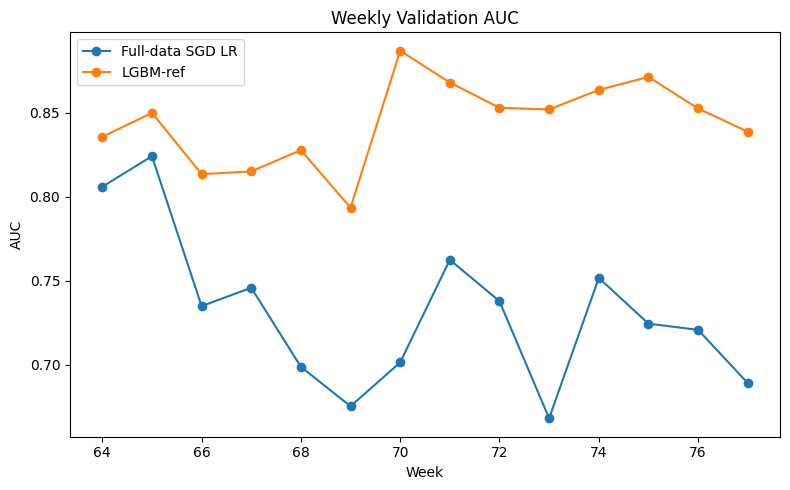

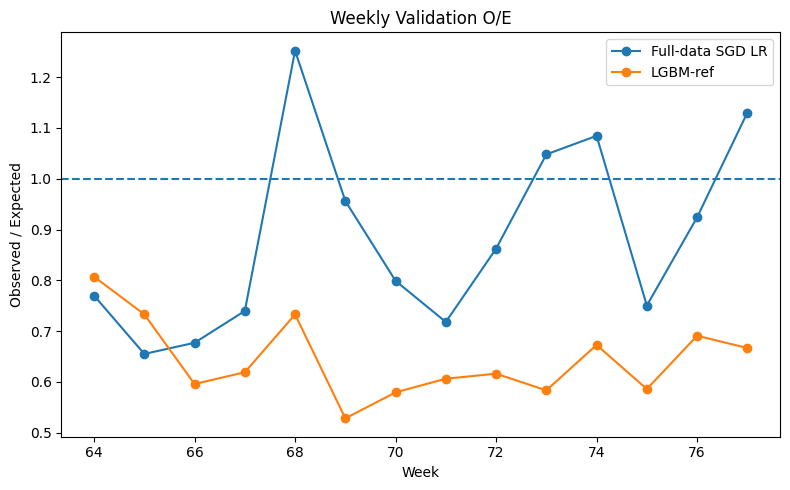

In [19]:
reference_model_metrics = pd.concat(
    [
        sgd_lr_metrics,
        lgbm_ref_metrics,
    ],
    ignore_index=True,
)


reference_weekly_metrics = pd.concat(
    [
        weekly_sgd_metrics,
        weekly_lgbm_metrics,
    ],
    ignore_index=True,
)


display(
    reference_model_metrics
)


# ------------------------------------------------------------
# Weekly AUC comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

for model_name, group in (
    reference_weekly_metrics
    .groupby("model")
):

    plt.plot(
        group[WEEK_COL],
        group["auc"],
        marker="o",
        label=model_name,
    )

plt.title(
    "Weekly Validation AUC"
)

plt.xlabel(
    "Week"
)

plt.ylabel(
    "AUC"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Weekly O/E comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

for model_name, group in (
    reference_weekly_metrics
    .groupby("model")
):

    plt.plot(
        group[WEEK_COL],
        group["oe_ratio"],
        marker="o",
        label=model_name,
    )

plt.axhline(
    1.0,
    linestyle="--",
)

plt.title(
    "Weekly Validation O/E"
)

plt.xlabel(
    "Week"
)

plt.ylabel(
    "Observed / Expected"
)

plt.legend()
plt.tight_layout()
plt.show()

In [20]:
lgbm_importance = pd.DataFrame({
    "feature": (
        lgbm_ref.feature_name()
    ),
    "gain_importance": (
        lgbm_ref.feature_importance(
            importance_type="gain",
            iteration=(
                lgbm_ref.best_iteration
            ),
        )
    ),
    "split_importance": (
        lgbm_ref.feature_importance(
            importance_type="split",
            iteration=(
                lgbm_ref.best_iteration
            ),
        )
    ),
})


gain_total = (
    lgbm_importance[
        "gain_importance"
    ].sum()
)


if gain_total > 0:

    lgbm_importance[
        "gain_share"
    ] = (
        lgbm_importance[
            "gain_importance"
        ]
        / gain_total
    )

else:

    lgbm_importance[
        "gain_share"
    ] = 0.0


lgbm_importance = (
    lgbm_importance
    .sort_values(
        "gain_importance",
        ascending=False,
    )
    .reset_index(drop=True)
)


lgbm_importance[
    "gain_rank"
] = np.arange(
    1,
    len(lgbm_importance) + 1,
)


display(
    lgbm_importance.head(30)
)

,feature,gain_importance,split_importance,gain_share,gain_rank
0,person_main_registaddr_district_1083M,77208.795479,2502,0.063297,1
1,person_main_contaddr_district_15M,63617.805336,2127,0.052155,2
2,previouscontdistrict_112M,59637.196865,2150,0.048891,3
3,avgdpdtolclosure24_3658938P,56004.858297,54,0.045913,4
4,person_main_empladdr_district_926M,37319.953413,1497,0.030595,5
5,pmts_dpd_1073P_mean,32014.683279,76,0.026246,6
6,dpdmaxdateyear_596T_mean,31869.819165,108,0.026127,7
7,maxdpdtolerance_577P_mean,28186.029850,48,0.023107,8
8,pmts_overdue_1140A_mean,22399.154631,52,0.018363,9
9,person_main_registaddr_zipcode_184M,20439.343444,804,0.016756,10


## 12. 基准结果沉淀与 Feature Selection 衔接

这一册最后只保存后续分析真正会继续使用的结果，不建立复杂的模型注册系统。

需要保留：

- eligible raw candidate feature list；
- numerical preprocessing statistics；
- categorical encoding rules 与 category-cap audit；
- SGD fixed-monitor training history；
- Full-data SGD LR 与 LGBM-ref 的整体指标；
- 两个模型的 Weekly Validation 指标与 uncertainty；
- LR risk-group calibration；
- LGBM early-stopping training history；
- LGBM Gain / Split Importance；
- Validation 逐样本预测；
- 本册固定的实验参数；
- 如果运行过，额外保存 50k vs 200k 的 bin-sample audit。

Notebook 8 接下来不需要重新猜测这一册发生过什么，而是可以直接从完整候选池和模型证据继续进入正式 Feature Selection。

运行完成后最重要的是回答四个问题：

1. Full-data SGD LR 是否已经训练到一个可信、基本稳定的线性 baseline；
2. 时间变化主要影响排序，还是主要影响概率校准；
3. 经过 Validation early stopping 的 LGBM-ref 是否发现明显额外的非线性预测信息；
4. 哪些 Feature Importance 值得在下一册继续验证，而不是立即删除或保留。

OOT 到这里仍然没有被读取。

In [21]:
# ------------------------------------------------------------
# 1. Eligible raw candidate feature list
# ------------------------------------------------------------

candidate_output = (
    candidate_catalog[
        [
            "column",
            "dtype",
            "dtype_family",
            "role",
            "origin",
        ]
    ]
    .rename(
        columns={"column": "feature"}
    )
)

candidate_output.to_csv(
    REPORT_ROOT
    / "nb7_candidate_features.csv",
    index=False,
)


# ------------------------------------------------------------
# 2. Metrics / diagnostics
# ------------------------------------------------------------

reference_model_metrics.to_csv(
    REPORT_ROOT
    / "reference_model_metrics.csv",
    index=False,
)
reference_weekly_metrics.to_csv(
    REPORT_ROOT
    / "reference_weekly_metrics.csv",
    index=False,
)
sgd_lr_calibration.to_csv(
    REPORT_ROOT
    / "full_sgd_lr_validation_calibration.csv",
    index=False,
)
lgbm_training_history.to_csv(
    REPORT_ROOT
    / "lgbm_training_history.csv",
    index=False,
)

if not bin_sample_audit.empty:
    bin_sample_audit.to_csv(
        REPORT_ROOT
        / "lgbm_bin_sample_audit.csv",
        index=False,
    )


# ------------------------------------------------------------
# 3. LGBM Importance
# ------------------------------------------------------------

lgbm_importance.to_csv(
    REPORT_ROOT
    / "lgbm_ref_importance.csv",
    index=False,
)


# ------------------------------------------------------------
# 4. Validation predictions
# ------------------------------------------------------------

validation_predictions.to_parquet(
    REPORT_ROOT
    / "validation_predictions.parquet",
    index=False,
    engine="pyarrow",
)


# ------------------------------------------------------------
# 5. Fixed experiment config
# ------------------------------------------------------------

nb7_config = {
    "random_seed": RANDOM_SEED,
    "candidate_feature_count": len(
        candidate_features
    ),
    "numeric_feature_count": len(
        numeric_features
    ),
    "categorical_feature_count": len(
        categorical_features
    ),
    "missing_indicator_count": len(
        missing_indicator_features
    ),
    "sgd_transformed_feature_count": len(
        model_feature_names
    ),
    "manual_exclude_features": (
        MANUAL_EXCLUDE_FEATURES
    ),
    "numeric_column_batch_size": (
        NUMERIC_COLUMN_BATCH_SIZE
    ),
    "categorical_column_batch_size": (
        CATEGORICAL_COLUMN_BATCH_SIZE
    ),
    "rare_category_min_frequency": (
        RARE_CATEGORY_MIN_FREQUENCY
    ),
    "max_categories_per_feature": (
        MAX_CATEGORIES_PER_FEATURE
    ),
    "sgd_epochs": SGD_EPOCHS,
    "sgd_alpha": SGD_ALPHA,
    "sgd_learning_rate": "constant",
    "sgd_eta0": SGD_ETA0,
    "sgd_average": True,
    "sgd_external_shuffle": True,
    "sgd_monitor_rows": SGD_MONITOR_ROWS,
    "sgd_monitor_every_row_groups": (
        SGD_MONITOR_EVERY_ROW_GROUPS
    ),
    "weekly_bootstrap_rounds": (
        WEEKLY_BOOTSTRAP_ROUNDS
    ),
    "lgbm_max_boost_round": (
        LGBM_MAX_BOOST_ROUND
    ),
    "lgbm_early_stopping_rounds": (
        LGBM_EARLY_STOPPING_ROUNDS
    ),
    "lgbm_best_iteration": int(
        lgbm_ref.best_iteration
    ),
    "lgbm_early_stopping_metric": (
        "binary_logloss"
    ),
    "lgbm_bin_construct_sample_cnt": (
        LGBM_BIN_SAMPLE_COUNT
    ),
    "lgbm_device_type": (
        LGBM_DEVICE_TYPE
    ),
    "lgbm_max_bin": (
        LGBM_MAX_BIN
    ),
    "lgbm_bin_audit_run": (
        RUN_LGBM_BIN_AUDIT
    ),
    "oot_read": False,
}

with open(
    REPORT_ROOT
    / "nb7_reference_model_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        nb7_config,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Notebook 7 outputs")
print(REPORT_ROOT)

Notebook 7 outputs
/content/drive/MyDrive/HomeCredit_Project/artifacts/nb07/final


### 13. 实验结果与主要发现（以保存的运行输出为准）

**实验设置：** Train 为 Week 0–63，Validation 为 Week 64–77；以下为当前 Colab / GPU-63 版本中保存的结果，不代表独立复现实验或最终模型。

| 指标 | SGD Logistic Regression | LightGBM Reference |
| --- | ---: | ---: |
| Train AUC | 0.829691 | 0.924199 |
| Validation AUC | 0.737423 | 0.852679 |
| Validation Gini | 0.474846 | 0.705358 |
| Validation KS | 0.397748 | 0.557300 |
| Validation Log-loss | 0.117628 | 0.094206 |
| Validation Observed Bad Rate | 2.4281% | 2.4281% |
| Validation Mean Predicted PD | 2.8206% | 3.7271% |
| Validation O/E | 0.860859 | 0.651484 |
| Validation Calibration Slope | 0.436598 | 0.994247 |

1. **线性基准模型可以学习有效的排序信号，但时间外性能下降。** SGD LR 的 Train AUC 为 0.8297，Validation AUC 为 0.7374，下降约 0.0923。其 Validation calibration slope 为 0.4366，提示不同风险组之间的预测概率差距偏大。该结果只能支持本次配置下存在时间外表现差异，不能单独证明 concept drift。

2. **LightGBM 在同一时间切分下提供更强的非线性参考。** 其 Train AUC 为 0.9242，Validation AUC 为 0.8527，下降约 0.0715；Validation Log-loss 低于 LR。由于两种模型的预处理不同，该比较反映各自完整建模流程的结果，不是单独控制模型形式的因果实验。

3. **排序能力与概率校准需要分别讨论。** LightGBM 的 Validation calibration slope 约 0.9942，但平均预测 PD 为 3.7271%，高于观察到的坏账率 2.4281%（O/E = 0.6515），显示整体概率偏高。LR 的平均预测 PD 为 2.8206%，更接近观察坏账率，但 calibration slope 仅 0.4366。整体平均风险接近并不等于分组或个体层面的校准良好。

4. **Validation 各周的模型表现存在波动。** LR 在 Week 64 和 Week 65 的 AUC 分别约为 0.8060 和 0.8242，Week 73 和 Week 77 约为 0.6682 和 0.6892；波动并非单调变化。部分周正例数较少，单周 AUC 应结合 bootstrap 置信区间解读，不宜将每个局部波动都解释为分布结构变化。

5. **后续分析方向。** 继续基于完整候选特征池验证预测时可用性、特征冗余、单变量信号及时间稳定性；对概率校准问题单独开展分析。OOT 在本 Notebook 中不参与训练与开发期模型评价。


### 14. 实验诊断与工程权衡

本阶段进行了 SGD 优化稳定性诊断，并针对数据规模采用流式训练与预测。以下记录可核验的技术决策，而非面试准备笔记。

1. **高维特征的标准化不足以保证 SGD 的步长安全。** 经过数值标准化后，当前运行的 3,494 维变换特征，其训练监控样本的 row norm 中位数约为 33.87，最大值约为 1,174；因此仍需根据样本尺度调整学习率。

2. **先用固定 Train 样本进行学习率诊断。** 在 20,000 条训练样本的对照实验中，`eta0=1e-4` 对应 AUC 约 0.7613、Log-loss 约 0.1339；更大的学习率出现概率分布异常和损失升高。正式全量训练选用 `eta0=1e-4`，不使用 Validation 选择迭代中途的停止点。

3. **训练有效性需要多指标诊断。** 每轮检查固定 monitor 的 Log-loss、AUC、平均预测 PD、预测分布离散程度和系数变化，避免将“代码能运行”等同于“模型正常学习”。本次第三个 epoch 结束时 monitor AUC 为 0.8299，Log-loss 为 0.1245；参数变化仍然存在，因此不声称严格收敛。

4. **内存约束决定实现方式。** 使用 PyArrow 分组读入、固定预处理、SGD `partial_fit`，保证全部 Train 样本参与线性基准训练，避免一次性展开完整高维矩阵。LightGBM 则采用 `Sequence` 和 GPU 直方图训练作为非线性参考；第 7 阶段使用 `max_bin=63`。

5. **区分训练稳定性、时间泛化和概率校准。** 本次 LR 与 LightGBM 的 Train–Validation 差距不同，且 Calibration Slope 与 O/E 并非同步改善。因此排序能力、整体概率水平与风险组校准应作为不同评估维度；不能只用单一 AUC 或 Log-loss 推断根本原因。

**下一阶段：** 基于特征可用性审查、稳健性与冗余证据推进 Feature Selection，并在保持 OOT 独立的前提下验证最终模型。
